# S Shape Functions Theory: Solved Exercises

> **About this Python edition.** A port of the Wolfram notebook [`S-Shape-Functions-Solved-Exercises.nb`](S-Shape-Functions-Solved-Exercises.nb) (PDF: [`S-Shape-Functions-Solved-Exercises.pdf`](S-Shape-Functions-Solved-Exercises.pdf)) to Python 3.14 with NumPy, SciPy, SymPy, Matplotlib, NetworkX and PyTorch. It is the companion to [S Shape Functions Theory](S-Shape-Functions-Theory.ipynb). The text, the numbering of problems, equations, figures and tables, and the cell indices (c.N.M) are the same as in the Wolfram notebook. All tables and figures are computed by the cells. Random numbers come from NumPy and PyTorch, not from Wolfram Language, so the values that depend on random weights (Problems 3, 5 and 6) differ a little from the Wolfram run; the text gives the values of this run.

*Worked solutions to the seven exercises of section 8 of S Shape Functions Theory, with derivations, tables and plots*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="28">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

This notebook solves the seven exercises at the end of S Shape Functions Theory, called the main notebook below. Each problem is stated, solved with a derivation, checked numerically and illustrated with plots. Problem 1 repeats the staircase experiment with the arctan and algebraic sigmoids. Their tails approach the limit 1 like 1/u and 1/${u}^{2}$ instead of ${e}^{-u}$, so every step leaks into its neighbours; to bring the leakage at N = 20 down to ${10}^{-3}$ takes λ ≈ 235 for the logistic, 401 for the algebraic and 6279 for the arctan sigmoid, and a tail formula predicts these values. Problem 2 shows that σ(t) + sin(t) exp(-${t}^{2}$) is sigmoidal but not monotone, overshooting to 1.068, and that its staircase still converges like 1/N, as Cybenko's theorem allows. Problem 3 uses the activations ${t}^{2}$ and ${t}^{3}$: the network can then produce only polynomials of degree 2 or 3, its hidden matrix has rank 6 or 10, and the error stops at that of the best polynomial (RMS 0.5 and 0.331), which is what the theorem of Leshno, Lin, Pinkus and Schocken predicts. Problem 4 writes x y z = exp(ln x + ln y + ln z) in the form of Kolmogorov's superposition formula and adds a four-cube identity valid for all real inputs. Problem 5 shows that one step of BasicRecurrentLayer is a Cybenko sum of the input (x, h), checks this against the real layer, and identifies the arrows that make it recurrent. Problem 6 derives the gradient with respect to the weights by the path rule, checks it against automatic differentiation and finite differences, and uses it to train an 8-unit network to a maximum error of 4 × ${10}^{-3}$, 7 times smaller than an 80-unit staircase. Problem 7 predicts the staircase rates ${N}^{-1/2}$ for x sin(1/x) and N to the power -ln 2/ln 3 = -0.631 for the Cantor staircase from their moduli of continuity, before measuring them, and the measurements confirm both. All results are computed in Python, and every figure is reproducible from the numbered code cells.

**Keywords:** sigmoidal function; staircase approximation; tail decay; non-monotone activation; polynomial activation; Leshno–Lin–Pinkus–Schocken theorem; Kolmogorov–Arnold superposition; BasicRecurrentLayer; backpropagation; gradient descent; modulus of continuity; Cantor staircase; Python; PyTorch

References of the form Eq. (M7), Figure M3, Table M3, Theorem M8 or cell c.13 of the main notebook point to S Shape Functions Theory. Equations, figures and tables of this notebook are numbered by problem: Eq. (3.2) is the second equation of Problem 3.

Every code cell starts with a comment such as `# c.3.4` giving its index: problem 3, cell 4. Run c.0 and c.0.1 first; after that each problem runs on its own, in order. Each notebook runs in its own Python kernel, so definitions from other notebooks cannot interfere with it; Kernel → Restart Kernel and Run All Cells gives a clean run from the top.

**Main notebook (Wolfram)**: S Shape Functions Theory  
https://www.wolframcloud.com/obj/ccn2/Published/S_Shape_Functions_Theory.nb

**CCN Node**:  
https://discuss.compclassnotes.com/t/s-shape-functions-theory/522

**CCN Wiki**:  
https://wiki.compclassnotes.com/books/neural-networks/page/s-shape-functions-theory   (.md)

## Index of problems, equations, figures, tables and code cells

### Problems

- Problem 1. The staircase with the arctan and algebraic sigmoids (c.1.1–c.1.8)
- Problem 2. A non-monotone sigmoidal function (c.2.1–c.2.6)
- Problem 3. The polynomial activation ${t}^{2}$ (c.3.1–c.3.6)
- Problem 4. x y z as a Kolmogorov superposition (c.4.1–c.4.6)
- Problem 5. One step of BasicRecurrentLayer as a Cybenko sum (c.5.1–c.5.6)
- Problem 6. The gradient with respect to the weights (c.6.1–c.6.7)
- Problem 7. Predicting rates from the modulus of continuity (c.7.1–c.7.7)

### Equations

- (1.1)–(1.5)  tails, steepness for a given tail, ideal staircase, leakage, required λ
- (2.1)–(2.2)  the non-monotone S-shape, an error bound
- (3.1)–(3.3)  a network with ${t}^{2}$ is a quadratic, dimension count, best polynomials
- (4.1)–(4.3)  the product as exp of a sum, its Kolmogorov form, the four-cube identity
- (5.1)–(5.3)  the recurrent step, the step as a Cybenko sum, unrolling
- (6.1)–(6.4)  the three weight gradients, the loss and its gradient
- (7.1)–(7.4)  the staircase bound, the moduli of x sin(1/x) and of the Cantor staircase

### Figures

- Figure 1.1–1.4. S-shapes and tails, staircases, leakage against λ, leakage at the nodes
- Figure 2.1–2.4. the non-monotone S-shape, its steepening, its staircase, convergence
- Figure 3.1–3.3. error floors, singular values, the learned surfaces
- Figure 4.1–4.3. the Kolmogorov network for x y z, the path of one input, level sets
- Figure 5.1–5.4. one step as in Figure M3, recurrent arrows, unrolling, the two computations
- Figure 6.1–6.3. training loss, the fit while training, the trained units
- Figure 7.1–7.4. the targets, moduli of continuity, rates, the error along x

### Tables

- Table 1.1–1.4. tails, Table M3 repeated, leakage measured and predicted, required λ
- Table 2.1–2.2. properties of the non-monotone S-shape, errors for three amplitudes
- Table 3.1–3.3. errors for three activations, best polynomials, ranks
- Table 5.1. weights of the layer and the agreement of the three computations
- Table 6.1–6.3. gradients checked, training history, trained network against staircases
- Table 7.1–7.3. moduli of continuity, predicted and measured errors, rates

## Settings and shared definitions

Libraries and settings for all figures and tables, as in the main notebook. figFont and tabFont set the font sizes of every figure and every table; wFull and wHalf keep every figure inside an A4 page when the notebook is printed or saved as PDF. logLine and logText draw reference lines and labels on log-log plots; nf, sci and mat format numbers as NumberForm, ScientificForm and MatrixForm do.

In [1]:
# c.0
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
from scipy.special import expit
from scipy.optimize import brentq
from scipy.ndimage import maximum_filter1d, minimum_filter1d
from IPython.display import display, HTML

figFont = 14      # font size in figures and diagrams
tabFont = 10      # font size in tables
wFull = 440 / 72  # full figure width in inches (440 pt); A4 text width is ~487 pt
wHalf = 215 / 72  # width of each panel in a two-column figure (215 pt)
plt.rcParams.update({
    "font.size": figFont, "axes.titlesize": figFont, "axes.labelsize": figFont,
    "legend.fontsize": figFont, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False})
C = [f"C{i}" for i in range(10)]   # the default colour sequence, like ColorData[97]

def logistic_sigmoid(t):
    """LogisticSigmoid: 1/(1 + e^(-t)), without overflow warnings."""
    return expit(t)

def unit_step(t):
    """UnitStep: 0 for t < 0 and 1 for t >= 0."""
    return np.heaviside(t, 1.0)

def table(rows, label):
    """A framed table with a grey header row and a bold label on top."""
    cell = f"border:1px solid #999;padding:3px 8px;text-align:left;font-size:{tabFont}pt"
    html = [f"<p style='font-weight:bold;font-size:{tabFont + 1}pt;margin-bottom:2px'>{label}</p>",
            "<table style='border-collapse:collapse'>"]
    for i, row in enumerate(rows):
        bg = "background:#ebebeb;" if i == 0 else ""
        html.append("<tr>" + "".join(f"<td style='{bg}{cell}'>{v}</td>" for v in row) + "</tr>")
    display(HTML("".join(html) + "</table>"))

def panels(rows, cols, label, h=0.78):
    """A grid of wHalf-wide panels with a figure label on top; returns the axes."""
    fig, axs = plt.subplots(rows, cols, figsize=(cols * wHalf + 0.6, rows * h * wHalf + 0.3), squeeze=False)
    fig.suptitle(label, fontsize=figFont)
    return fig, axs

def legend_below(ax, ncol=4, **kw):
    """Legend under the plot, like Placed[LineLegend[...], Below]."""
    kw.setdefault("bbox_to_anchor", (0.5, -0.2))
    ax.legend(loc="upper center", ncol=ncol, **kw)

def nf(x, d=3):
    """NumberForm[x, d]: x with d significant digits."""
    return np.format_float_positional(float(x), precision=d, unique=False, fractional=False, trim="-")

def sci(x):
    """ScientificForm[x, 2]: 2.2 × 10^-16."""
    if x == 0:
        return "0"
    e = int(np.floor(np.log10(abs(x))))
    m = round(x / 10.0**e, 1)
    if abs(m) >= 10:
        m, e = m / 10, e + 1
    return f"{m:.1f} × 10<sup>{e}</sup>"

def mat(m, d=3):
    """A matrix or vector with d significant digits."""
    m = np.asarray(m)
    if m.ndim == 1:
        return "[" + ", ".join(nf(v, d) for v in m) + "]"
    return "[" + ", ".join(mat(r, d) for r in m) + "]"

# reference lines and labels on log-log plots, given in plot units
def logLine(ax, pts):
    pts = np.asarray(pts, float)
    ax.plot(pts[:, 0], pts[:, 1], "--", color="gray", lw=1)

def logText(ax, s, pt):
    ax.text(*pt, s, color="gray", fontsize=figFont - 2, ha="center", va="center")

Example A of the main notebook, f(x) = sin(2πx) + x²/2, and a vectorized version of the staircase of Eq. (M7) that accepts any S-shape. The last line checks it against stair of cell c.8 of the main notebook; the difference is at the level of rounding.

In [2]:
# c.0.1
# example A of the main notebook, section 4
def f(x):
    return np.sin(2 * np.pi * x) + x**2 / 2

# the staircase of Eq. (M7) for any S-shape s, on an array of points xs;
# vals = values of the target at the nodes 0, 1/N, ..., 1
def stairOn(s, vals, lam, xs):
    vals = np.asarray(vals, float)
    n = len(vals) - 1
    c = (np.arange(1, n + 1) - 1 / 2) / n
    return vals[0] + s(lam * (np.asarray(xs, float)[:, None] - c)) @ np.diff(vals)

def nodes(n):
    return np.arange(n + 1) / n

xsFine = np.linspace(0., 1., 2001)   # step 0.0005
def supErrS(s, fun, n, lam):
    return np.max(np.abs(fun(xsFine) - stairOn(s, fun(nodes(n)), lam, xsFine)))

# check: stairOn agrees with stair of the main notebook, c.8 (summed term by term)
def stair(fun, n, lam):
    return lambda x: fun(0.) + sum((fun(k / n) - fun((k - 1) / n)) * logistic_sigmoid(lam * (x - (k - 1 / 2) / n))
                                   for k in range(1, n + 1))

pts3 = np.array([0.13, 0.5, 0.77])
np.max(np.abs(stairOn(logistic_sigmoid, f(nodes(10)), 200, pts3) - np.array([stair(f, 10, 200)(x) for x in pts3])))

np.float64(8.326672684688674e-17)

## 1. Problem 1: the staircase with arctan and algebraic sigmoids

**Problem 1.** Repeat the staircase experiment of section 4 (Table M3) with the arctan and algebraic sigmoids. Why do you need a larger λ for the same error?

### The three S-shapes and their tails

The three functions are the logistic σ(t) = 1/(1 + ${e}^{-t}$), the arctan sigmoid 1/2 + arctan(t)/π and the algebraic sigmoid (1 + t/√(1 + ${t}^{2}$))/2. All three are sigmoidal in the sense of Eq. (M1) and all three are symmetric, σ(-t) = 1 - σ(t). What separates them is how fast they reach their limits. Write T(u) = 1 - σ(u) for the tail, the distance from the limit 1 at u > 0. By symmetry the same T(u) is the distance from the limit 0 at -u. As u → ∞,

$$
1 - \sigma ( u ) \sim \begin{cases}{e}^{- u} & \text{logistic} \\ \frac{1}{\pi u} & \text{arctan} \\ \frac{1}{4 {u}^{2}} & \text{algebraic}\end{cases} \quad  u \to \infty \quad  \tag{1.1}
$$

The logistic tail is exponential; the other two are algebraic, and the arctan tail is the slowest of all: at u = 1000 it is still 3 × ${10}^{-4}$. Solving T(u) = η for u gives the steepness at which each function is within η of its limit:

$$
{u}_{\eta} = \begin{cases}\log  ( \frac{1 - \eta}{\eta} ) & \text{logistic} \\ \cot  ( \pi \eta ) & \text{arctan} \\ \frac{1 - 2 \eta}{2 \sqrt{\eta ( 1 - \eta )}} & \text{algebraic}\end{cases} \quad  \tag{1.2}
$$

For η = ${10}^{-6}$ the logistic needs u ≈ 14, the algebraic sigmoid u ≈ 500 and the arctan sigmoid u ≈ 318000: the logistic grows like ln(1/η), the algebraic like 1/(2√η) and the arctan like 1/(πη).

*Figure 1.1. Left: the three S-shapes. Right: their tails 1 - σ(u) on log-log axes, with the leading terms 1/(πu) and 1/(4${u}^{2}$) of Eq. (1.1) dashed. The logistic tail falls off the bottom of the plot near u = 18.*

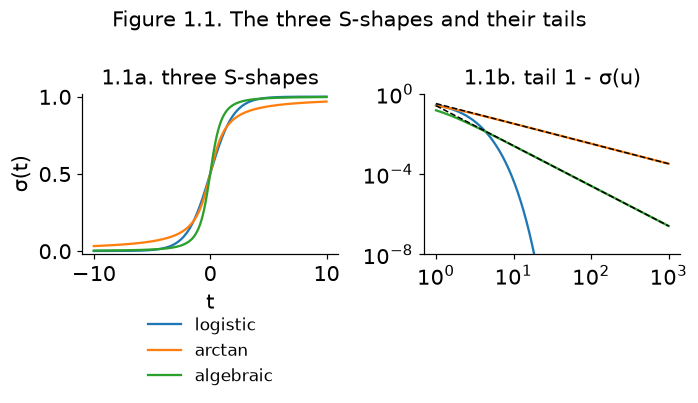

In [3]:
# c.1.1
sig3 = {"logistic": logistic_sigmoid,
        "arctan": lambda t: 1 / 2 + np.arctan(t) / np.pi,
        "algebraic": lambda t: (1 + t / np.sqrt(1 + t**2)) / 2}
# the tail 1 - σ(u): distance to the limit 1. All three satisfy
# σ(-u) = 1 - σ(u), so σ(-u) gives the tail without round-off
def tail(k):
    return lambda u: sig3[k](-u)

fig, axs = panels(1, 2, "Figure 1.1. The three S-shapes and their tails", h=1.35)
a1, a2 = axs[0]
t = np.linspace(-10, 10, 801)
for k, fn in sig3.items():
    a1.plot(t, fn(t), label=k)
a1.set(ylim=(-0.02, 1.02), xlabel="t", ylabel="σ(t)", title="1.1a. three S-shapes")
legend_below(a1, ncol=1, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.3))
u = np.logspace(0, 3, 400)
for i, k in enumerate(sig3):
    a2.loglog(u, tail(k)(u), color=C[i])
a2.loglog(u, 1 / (np.pi * u), "k--", lw=1)
a2.loglog(u, 1 / (4 * u**2), "k--", lw=1)
a2.set(ylim=(1e-8, 1), xticks=[1, 10, 100, 1000], title="1.1b. tail 1 - σ(u)")
fig.tight_layout()
plt.show()

*Table 1.1. Each tail divided by its leading term tends to 1, as Eq. (1.1) states. The closed forms u(η) of Eq. (1.2), a numerical check of them, and their values.*

In [4]:
# c.1.2
u, eta = sp.symbols("u η", positive=True)
# leading term of each tail, Eq. (1.1)
lead = {"logistic": sp.exp(-u), "arctan": 1 / (sp.pi * u), "algebraic": 1 / (4 * u**2)}
tailSym = {"logistic": 1 / (1 + sp.exp(u)), "arctan": sp.Rational(1, 2) - sp.atan(u) / sp.pi,
           "algebraic": (1 - u / sp.sqrt(1 + u**2)) / 2}
# the steepness u at which the tail falls to η, Eq. (1.2)
uOf = {"logistic": sp.log((1 - eta) / eta), "arctan": sp.cot(sp.pi * eta),
       "algebraic": (1 - 2 * eta) / (2 * sp.sqrt(eta * (1 - eta)))}
def pretty(e):
    return str(e).replace("**", "^").replace("*", " ").replace("pi", "π")

rows = [["σ", "tail / lead", "u(η)", "check: rel. error", "η = 0.01", "η = 0.001", "η = 10<sup>-6</sup>"]]
for k in sig3:
    uf = sp.lambdify(eta, uOf[k], "numpy")
    etas = 10.0**-np.arange(1, 7)
    check = np.max(np.abs(tail(k)(uf(etas)) - etas) / etas)
    rows.append([k, sp.limit(tailSym[k] / lead[k], u, sp.oo), pretty(uOf[k]), sci(check)]
                + [nf(uf(e), 4) for e in (1e-2, 1e-3, 1e-6)])
table(rows, "Table 1.1")

σ,tail / lead,u(η),check: rel. error,η = 0.01,η = 0.001,η = 10-6
logistic,1,log((1 - η)/η),8.5 × 10-16,4.595,6.907,13.82
arctan,1,cot(π η),2.7 × 10-11,31.82,318.3,318300
algebraic,1,(1 - 2 η)/(2 sqrt(η) sqrt(1 - η)),2.9 × 10-11,4.925,15.79,500


**Table 1.1**

| σ | tail / lead | u(η) | check: rel. error | η = 0.01 | η = 0.001 | η = 10<sup>-6</sup> |
|---|---|---|---|---|---|---|
| logistic | 1 | $\log \left(\frac{1-\eta }{\eta }\right)$ | 8.5 × 10<sup>-16</sup> | 4.595 | 6.907 | 13.82 |
| arctan | 1 | $\cot (\pi  \eta )$ | 2.7 × 10<sup>-11</sup> | 31.82 | 318.3 | 318300. |
| algebraic | 1 | $\frac{1-2 \eta }{2 \sqrt{(1-\eta ) \eta }}$ | 2.7 × 10<sup>-11</sup> | 4.925 | 15.79 | 500.0 |

### Table M3 repeated

First the experiment as asked: the staircase ${G}_{N}$ of Eq. (M7), with steepness λ = 20 N as in Table M3, built from each of the three S-shapes, and its largest error on [0, 1] for example A.

*Table 1.2. Sup-norm error of ${G}_{N}$ for example A with each S-shape, λ = 20 N.*

In [5]:
# c.1.3
# Table M3, row A, repeated with each S-shape, λ = 20 N
table([["σ", "N = 5", "N = 10", "N = 20", "N = 40", "N = 80"]] +
      [[k] + [nf(supErrS(s, f, n, 20 * n), 3) for n in (5, 10, 20, 40, 80)] for k, s in sig3.items()],
      "Table 1.2")

σ,N = 5,N = 10,N = 20,N = 40,N = 80
logistic,0.442,0.22,0.11,0.0551,0.0276
arctan,0.401,0.186,0.0961,0.0518,0.027
algebraic,0.5,0.252,0.126,0.063,0.0316


**Table 1.2**

| σ | N = 5 | N = 10 | N = 20 | N = 40 | N = 80 |
|---|---|---|---|---|---|
| logistic | 0.442 | 0.22 | 0.11 | 0.0551 | 0.0276 |
| arctan | 0.401 | 0.186 | 0.0961 | 0.0518 | 0.027 |
| algebraic | 0.5 | 0.252 | 0.126 | 0.063 | 0.0316 |

A surprise: at λ = 20 N the three errors are almost the same, and the arctan staircase is even slightly better. The sup-norm error here is dominated by the coarseness of the staircase, which is O(1/N) whatever the S-shape, and a softer step even rounds the corners of the staircase a little. To see where the S-shape matters, compare ${G}_{N}$ with the ideal staircase ${S}_{N}$ of hard steps, the limit λ → ∞ used in the proof of Lemma M1:

$$
\begin{gathered}{S}_{N} ( x ) = f ( 0 ) + {\sum}_{k = 1}^{N} {\Delta}_{k} \  H ( x - {c}_{k} ) \\ {\Delta}_{k} = f ( \frac{k}{N} ) - f ( \frac{k - 1}{N} ) , {c}_{k} = \frac{k - \frac{1}{2}}{N} , {S}_{N} ( \frac{k}{N} ) = f ( \frac{k}{N} )\end{gathered} \quad  \tag{1.3}
$$

${S}_{N}$ is exact at the nodes k/N, which lie halfway between two step positions ${c}_{k}$. So any error of ${G}_{N}$ at a node is caused by the tails of the steps alone. We call it leakage.

*Figure 1.2. Top: ${G}_{10}$ with λ = 200 for the three S-shapes, nearly indistinguishable. Bottom: the distance |${G}_{10}$ - ${S}_{10}$| on a log scale. At the nodes (grid lines) it falls to about ${10}^{-6}$ for the logistic and to between ${10}^{-4}$ and ${10}^{-3}$ for the algebraic sigmoid, and stays near ${10}^{-2}$ for the arctan sigmoid.*

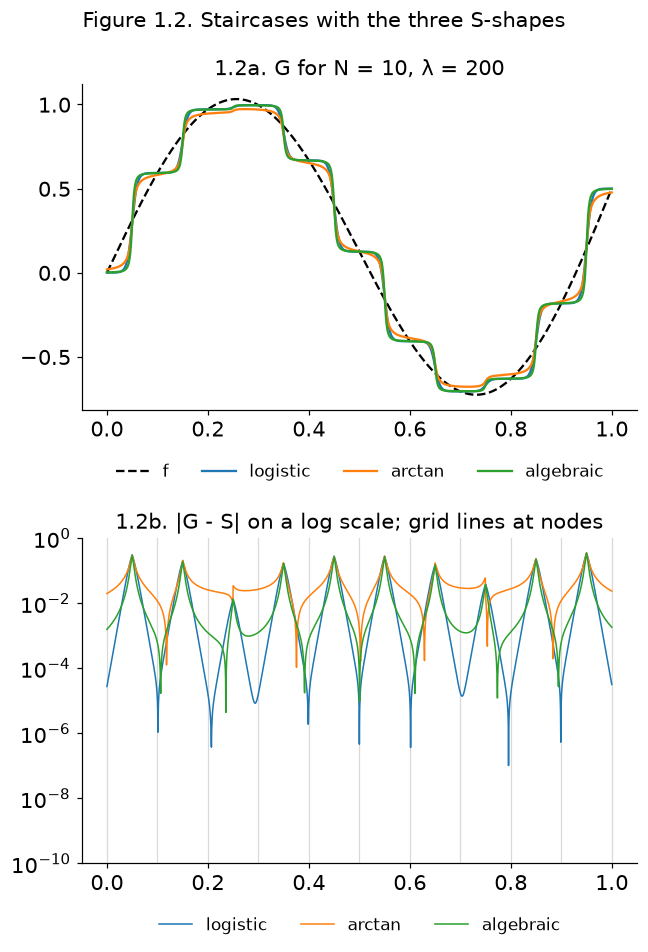

In [6]:
# c.1.4
# the ideal staircase S_N of hard steps, Eq. (1.3)
def stepStair(vals, xs):
    return stairOn(unit_step, vals, 1, xs)

gAll = {k: stairOn(s, f(nodes(10)), 200, xsFine) for k, s in sig3.items()}
fig, (a1, a2) = plt.subplots(2, 1, figsize=(wFull, 1.45 * wFull))
fig.suptitle("Figure 1.2. Staircases with the three S-shapes", fontsize=figFont)
a1.plot(xsFine, f(xsFine), "k--", label="f")
for i, (k, gk) in enumerate(gAll.items()):
    a1.plot(xsFine, gk, color=C[i], label=k)
a1.set_title("1.2a. G for N = 10, λ = 200")
legend_below(a1, ncol=4, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.12))
S10 = stepStair(f(nodes(10)), xsFine)
for i, (k, gk) in enumerate(gAll.items()):
    a2.semilogy(xsFine, np.abs(gk - S10) + 1e-16, color=C[i], label=k, lw=1)
for xn in nodes(10):
    a2.axvline(xn, color="0.85", lw=0.8, zorder=0)
a2.set(ylim=(1e-10, 1), title="1.2b. |G - S| on a log scale; grid lines at nodes")
legend_below(a2, ncol=3, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

### The leakage and its formula

At a node ${x}_{k}$ every step to its left has risen to 1 - T and every step to its right has risen to T. With the symmetry σ(-u) = 1 - σ(u), the leakage is exactly

$$
\begin{gathered}{G}_{N} ( {x}_{k} ) - f ( {x}_{k} ) = - \sum_{m} \operatorname{sgn}  ( {x}_{k} - {c}_{m} ) \  {\Delta}_{m} \  T ( \lambda | {x}_{k} - {c}_{m} | ) \\ T ( u ) = 1 - \sigma ( u ) = \sigma ( - u ) , {x}_{k} = \frac{k}{N}\end{gathered} \quad  \tag{1.4}
$$

Each jump ${\Delta}_{m}$ of f contributes its height times the tail at the scaled distance from the node. Replacing T by its leading term from Eq. (1.1) turns Eq. (1.4) into a prediction, without any fitting. For the logistic only the two nearest steps, at distance 1/(2N), matter, and the leakage falls like exp(-λ/(2N)). For the algebraic sigmoid every step contributes and the leakage falls like 1/${\lambda}^{2}$. For the arctan sigmoid it falls only like 1/λ, and the sum over all steps does not cancel.

*Table 1.3. Leakage at N = 20, measured and predicted by Eq. (1.4). From λ = 400 on, the predictions agree with the measurements to two digits. The logistic measurement stops at about ${10}^{-16}$, the rounding level of machine numbers.*

In [7]:
# c.1.5
# leakage: error at the nodes k/N, where the ideal staircase is exact
def leakAt(s, n, lam):
    return stairOn(s, f(nodes(n)), lam, nodes(n)) - f(nodes(n))

def leak(s, n, lam):
    return np.max(np.abs(leakAt(s, n, lam)))

# prediction of Eq. (1.4): each tail replaced by its leading term
leadNum = {k: sp.lambdify(u, e, "numpy") for k, e in lead.items()}
def predAt(k, n, lam):
    d = np.diff(f(nodes(n)))
    c = (np.arange(1, n + 1) - 1 / 2) / n
    x = nodes(n)[:, None]
    with np.errstate(under="ignore"):
        return -np.sum(np.sign(x - c) * d * leadNum[k](lam * np.abs(x - c)), axis=1)

def predLeak(k, n, lam):
    return np.max(np.abs(predAt(k, n, lam)))

lams = [100, 400, 1600, 6400, 25600]
rows = [["σ", ""] + [f"λ = {l}" for l in lams]]
for k, s in sig3.items():
    rows.append([k, "measured"] + [sci(leak(s, 20, l)) for l in lams])
    rows.append(["", "Eq. (1.4)"] + [sci(predLeak(k, 20, l)) for l in lams])
table(rows, "Table 1.3")

σ,,λ = 100,λ = 400,λ = 1600,λ = 6400,λ = 25600
logistic,measured,2.7 × 10-2,1.6 × 10-5,1.1 × 10-16,1.1 × 10-16,1.1 × 10-16
,Eq. (1.4),3.0 × 10-2,1.6 × 10-5,1.5 × 10-18,1.2 × 10-70,4.0 × 10-279
arctan,measured,6.0 × 10-2,1.6 × 10-2,3.9 × 10-3,9.8 × 10-4,2.5 × 10-4
,Eq. (1.4),6.3 × 10-2,1.6 × 10-2,3.9 × 10-3,9.8 × 10-4,2.5 × 10-4
algebraic,measured,1.5 × 10-2,1.0 × 10-3,6.3 × 10-5,4.0 × 10-6,2.5 × 10-7
,Eq. (1.4),1.6 × 10-2,1.0 × 10-3,6.3 × 10-5,4.0 × 10-6,2.5 × 10-7


**Table 1.3**

| σ |  | λ = 100 | λ = 400 | λ = 1600 | λ = 6400 | λ = 25600 |
|---|---|---|---|---|---|---|
| logistic | measured | 2.7 × 10<sup>-2</sup> | 1.6 × 10<sup>-5</sup> | 5.6 × 10<sup>-17</sup> | 5.6 × 10<sup>-17</sup> | 5.6 × 10<sup>-17</sup> |
|  | Eq. (1.4) | 3.0 × 10<sup>-2</sup> | 1.6 × 10<sup>-5</sup> | 1.5 × 10<sup>-18</sup> | 1.2 × 10<sup>-70</sup> | 4.0 × 10<sup>-279</sup> |
| arctan | measured | 6.0 × 10<sup>-2</sup> | 1.6 × 10<sup>-2</sup> | 3.9 × 10<sup>-3</sup> | 9.8 × 10<sup>-4</sup> | 2.5 × 10<sup>-4</sup> |
|  | Eq. (1.4) | 6.3 × 10<sup>-2</sup> | 1.6 × 10<sup>-2</sup> | 3.9 × 10<sup>-3</sup> | 9.8 × 10<sup>-4</sup> | 2.5 × 10<sup>-4</sup> |
| algebraic | measured | 1.5 × 10<sup>-2</sup> | 1.0 × 10<sup>-3</sup> | 6.3 × 10<sup>-5</sup> | 4.0 × 10<sup>-6</sup> | 2.5 × 10<sup>-7</sup> |
|  | Eq. (1.4) | 1.6 × 10<sup>-2</sup> | 1.0 × 10<sup>-3</sup> | 6.3 × 10<sup>-5</sup> | 4.0 × 10<sup>-6</sup> | 2.5 × 10<sup>-7</sup> |

*Figure 1.3. Leakage against λ at N = 20. The logistic plunges, the algebraic sigmoid follows slope -2 and the arctan sigmoid slope -1, as Eq. (1.4) predicts.*

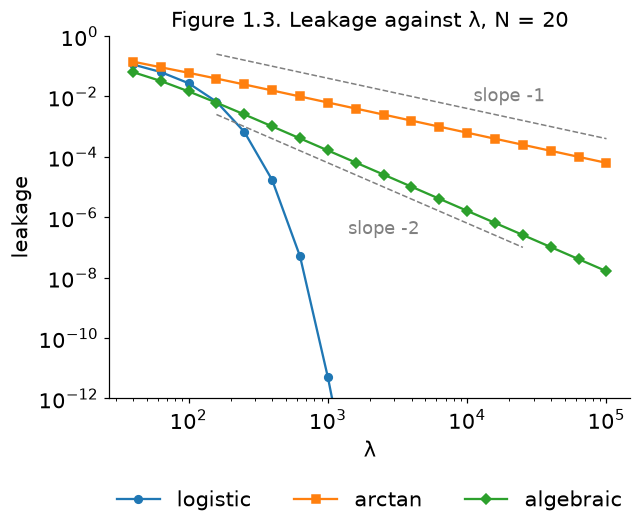

In [8]:
# c.1.6
lamGrid = 10.0**np.arange(1.6, 5.01, 0.2)
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
mk = ["o", "s", "D"]
for i, (k, s) in enumerate(sig3.items()):
    ax.loglog(lamGrid, [max(leak(s, 20, l), 1e-16) for l in lamGrid], marker=mk[i], ms=5, label=k)
logLine(ax, [[10**2.2, 10**-0.6], [10**5, 10**-3.4]])
logLine(ax, [[10**2.2, 10**-2.6], [10**4.4, 10**-7.]])
logText(ax, "slope -1", (10**4.3, 10**-2.))
logText(ax, "slope -2", (10**3.4, 10**-6.4))
ax.set(ylim=(1e-12, 1), xlabel="λ", ylabel="leakage", title="Figure 1.3. Leakage against λ, N = 20")
legend_below(ax, ncol=3)
plt.show()

### How large must λ be?

Setting the leakage equal to a tolerance η and solving for λ gives the answer to the question. Write ${L}_{1}$ and ${L}_{2}$ for the largest leakage of the arctan and algebraic sigmoids at λ = 1, computed from Eq. (1.4) with the leading terms; then the leakage is ${L}_{1}$/λ and ${L}_{2}$/${\lambda}^{2}$, and

$$
{\lambda}_{\text{logistic}} \approx 2 N \  \log  ( \frac{| {\Delta}_{N} |}{\eta} ) , {\lambda}_{\text{arctan}} \approx \frac{{L}_{1}}{\eta} , {\lambda}_{\text{algebraic}} \approx \sqrt{\frac{{L}_{2}}{\eta}} \quad  \tag{1.5}
$$

*Table 1.4. The λ needed for a leakage of ${10}^{-3}$, found by root finding, against Eq. (1.5).*

In [9]:
# c.1.7
# the λ that brings the leakage down to η = 10^-3, measured
def lamNeed(s, n, eta):
    g = lambda l: np.log(max(leak(s, n, np.exp(l)), 1e-300)) - np.log(eta)
    return np.exp(brentq(g, np.log(5. * n), np.log(1e6)))

# and predicted: logistic from the end point, the others from
# Eq. (1.4) scaled by 1/λ or 1/λ², Eq. (1.5)
def lamPred(n, eta):
    return [2 * n * np.log(abs(np.diff(f(nodes(n)))[-1]) / eta),
            predLeak("arctan", n, 1) / eta,
            np.sqrt(predLeak("algebraic", n, 1) / eta)]

rows = [["N", "", "logistic", "arctan", "algebraic"]]
for n in (10, 20, 40):
    rows.append([n, "measured"] + [round(lamNeed(s, n, 1e-3)) for s in sig3.values()])
    rows.append(["", "Eq. (1.5)"] + [round(v) for v in lamPred(n, 1e-3)])
table(rows, "Table 1.4")

N,,logistic,arctan,algebraic
10,measured,130,5790,268
,Eq. (1.5),131,5790,268
20,measured,235,6279,401
,Eq. (1.5),235,6279,403
40,measured,415,7903,581
,Eq. (1.5),416,7903,585


**Table 1.4**

| N |  | logistic | arctan | algebraic |
|---|---|---|---|---|
| 10 | measured | 130 | 5790 | 268 |
|  | Eq. (1.5) | 131 | 5790 | 268 |
| 20 | measured | 235 | 6279 | 401 |
|  | Eq. (1.5) | 235 | 6279 | 403 |
| 40 | measured | 415 | 7903 | 581 |
|  | Eq. (1.5) | 416 | 7903 | 585 |

For N = 20 the arctan sigmoid needs λ ≈ 6300, 27 times more than the logistic; the algebraic sigmoid needs 1.7 times more. The logistic requirement grows roughly in proportion to N and the arctan requirement only logarithmically (through ${L}_{1}$), so the ratio shrinks as N grows, but for any tolerance the order logistic < algebraic < arctan holds, and the gap widens as η shrinks, because of Eq. (1.2).

*Figure 1.4. The signed leakage at every node, N = 20, λ = 400. For the logistic and algebraic sigmoids the contributions of neighbouring steps cancel in the interior. For the arctan sigmoid they do not: the leakage follows the shape of -sin(2πx), and Eq. (1.4) (dashed) reproduces it point by point.*

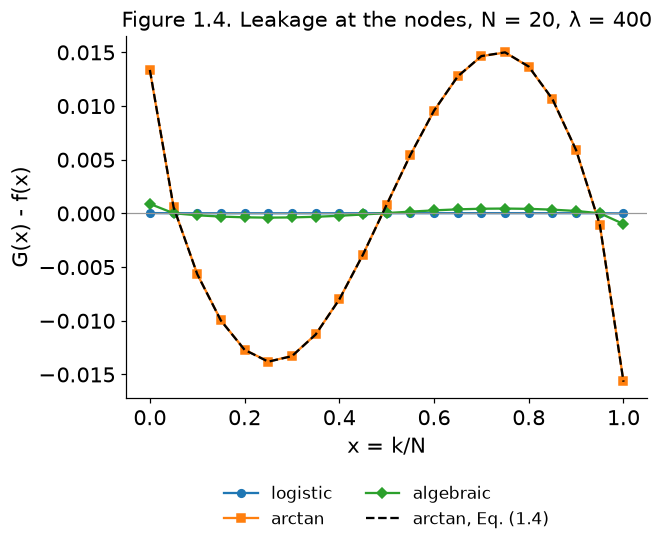

In [10]:
# c.1.8
# where the leakage sits: signed error at each node, N = 20, λ = 400;
# dashed: the arctan prediction of Eq. (1.4)
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
for i, (k, s) in enumerate(sig3.items()):
    ax.plot(nodes(20), leakAt(s, 20, 400), marker=mk[i], ms=5, label=k)
ax.plot(nodes(20), predAt("arctan", 20, 400), "k--", label="arctan, Eq. (1.4)")
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="x = k/N", ylabel="G(x) - f(x)", title="Figure 1.4. Leakage at the nodes, N = 20, λ = 400")
legend_below(ax, ncol=2, fontsize=figFont - 3)
plt.show()

The shape in Figure 1.4 has a name. With T(u) ≈ 1/(πu), Eq. (1.4) becomes, for large N, -(1/(πλ)) times the principal-value integral of f′(s)/(x - s) over [0, 1]: a truncated Hilbert transform of f′. The Hilbert transform of a cosine is a sine, and f′ is dominated by 2π cos(2πx). A tail as heavy as 1/u reaches every step of the staircase.

### Answer

With λ = 20 N, as in Table M3, the three S-shapes give almost the same sup-norm error, because the error is set by the coarseness of the staircase. The S-shape matters in how quickly ${G}_{N}$ approaches the ideal staircase of hard steps, which is the limit used in Cybenko's proof. A sigmoid reaches its limits at the rate of its tail, Eq. (1.1): exponentially for the logistic, like 1/${u}^{2}$ for the algebraic and like 1/u for the arctan sigmoid. Each step leaks its tail into the neighbouring nodes, Eq. (1.4), so the slower the tail, the larger λ must be for the same leakage, Eq. (1.5) and Table 1.4. For a leakage of ${10}^{-3}$ at N = 20: λ ≈ 235, 401 and 6279.

## 2. Problem 2: a sigmoidal function that is not monotone

**Problem 2.** Try a non-monotone function such as σ(t) + sin(t) exp(-${t}^{2}$). Is it sigmoidal in the sense of Eq. (M1), and does the staircase still converge?

### Is it sigmoidal?

Write s for the new function:

$$
s ( t ) = \sigma ( t ) + \sin  \  t \  {e}^{- {t}^{2}} , \lim _{t \to - \infty} \  s ( t ) = 0 , \lim _{t \to + \infty} \  s ( t ) = 1 \quad  \tag{2.1}
$$

Since |sin(t) exp(-${t}^{2}$)| ≤ exp(-${t}^{2}$) → 0, the added term disappears at both ends and the limits are those of σ: 0 and 1. That is all Eq. (M1) asks for, so s is sigmoidal. It is also continuous, and it keeps the symmetry s(-t) = 1 - s(t), because sin is odd. But it is not monotone. Its derivative changes sign four times in (-4, 4). s rises above 1, to 1.068 at t = 0.784, and by symmetry dips below 0, to -0.068 at t = -0.784.

*Table 2.1. Properties of s, computed symbolically and numerically.*

In [11]:
# c.2.1
t = sp.symbols("t", real=True)
s2 = 1 / (1 + sp.exp(-t)) + sp.sin(t) * sp.exp(-t**2)
ds2 = sp.lambdify(t, sp.diff(s2, t), "numpy")
s2f = sp.lambdify(t, s2, "numpy")
def zeros(fn, a, b, n=4001):
    """All sign changes of fn on [a, b], refined by bisection (like NSolve on an interval)."""
    xs = np.linspace(a, b, n)
    v = fn(xs)
    return [brentq(fn, xs[i], xs[i + 1]) for i in np.nonzero(np.sign(v[:-1]) != np.sign(v[1:]))[0]]

tMin, tMax = zeros(ds2, -1, 1)[0], zeros(ds2, -1, 1)[-1]
table([
    ["property", "value"],
    ["limit t → -∞", sp.limit(s2, t, -sp.oo)],
    ["limit t → +∞", sp.limit(s2, t, sp.oo)],
    ["sigmoidal, Eq. (M1)?", "yes"],
    ["σ(-t) = 1 - σ(t)?", sp.simplify(s2.subs(t, -t) - (1 - s2)) == 0],
    ["largest value", f"{nf(s2f(tMax), 4)} at t = {nf(tMax, 4)}"],
    ["smallest value", f"{nf(s2f(tMin), 4)} at t = {nf(tMin, 4)}"],
    ["zeros of σ' in (-4, 4)", "{" + ", ".join(nf(z, 4) for z in zeros(ds2, -4, 4)) + "}"],
    ["monotone?", "no: σ' < 0 on two intervals"]], "Table 2.1")

property,value
limit t → -∞,0
limit t → +∞,1
"sigmoidal, Eq. (M1)?",yes
σ(-t) = 1 - σ(t)?,True
largest value,1.068 at t = 0.7836
smallest value,-0.06843 at t = -0.7836
"zeros of σ' in (-4, 4)","{-1.875, -0.7836, 0.7836, 1.875}"
monotone?,no: σ' < 0 on two intervals


**Table 2.1**

| property | value |
|---|---|
| limit t → -∞ | 0 |
| limit t → +∞ | 1 |
| sigmoidal, Eq. (M1)? | yes |
| σ(-t) = 1 - σ(t)? | True |
| largest value | 1.068 at t = 0.7836 |
| smallest value | -0.06843 at t = -0.7836 |
| zeros of σ' in (-4, 4) | {-1.875, -0.7836, 0.7836, 1.875} |
| monotone? | no: σ' < 0 on two intervals |

*Figure 2.1. Left: s (solid) against the logistic (dashed), with the levels 0 and 1. Right: s′, positive (green) and negative (red).*

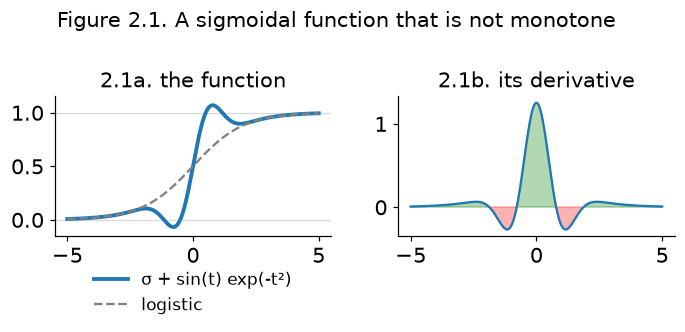

In [12]:
# c.2.2
fig, axs = panels(1, 2, "Figure 2.1. A sigmoidal function that is not monotone", h=1.0)
a1, a2 = axs[0]
tt = np.linspace(-5, 5, 1001)
a1.plot(tt, s2f(tt), lw=2.5, label="σ + sin(t) exp(-t²)")
a1.plot(tt, logistic_sigmoid(tt), "--", color="gray", label="logistic")
for lv in (0, 1):
    a1.axhline(lv, color="0.85", lw=0.8, zorder=0)
a1.set(ylim=(-0.15, 1.15), title="2.1a. the function")
legend_below(a1, ncol=1, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.15))
d = ds2(tt)
a2.plot(tt, d, color="C0")
a2.fill_between(tt, d, 0, where=d >= 0, color="green", alpha=0.3)
a2.fill_between(tt, d, 0, where=d < 0, color="red", alpha=0.3)
a2.set_title("2.1b. its derivative")
fig.tight_layout()
plt.show()

Cybenko's Theorem M2 needs only continuity and the two limits of Eq. (M1). Monotonicity is never used: Lemma M1 needs only that s(λt) tends to the step as λ → ∞, for every t ≠ 0, with s bounded. Figure 2.2 shows exactly that. The overshoot keeps its height, 0.068, but is pushed into a window of width about 1/λ around 0. By contrast Theorem M6, of Hornik, Stinchcombe and White, assumes a squashing function, which is nondecreasing, and so does not apply to s. Theorems M7 and M8 do apply, since s is bounded, continuous and not a polynomial.

*Figure 2.2. s(λt) for λ = 1, 4, 16 against the step (dashed).*

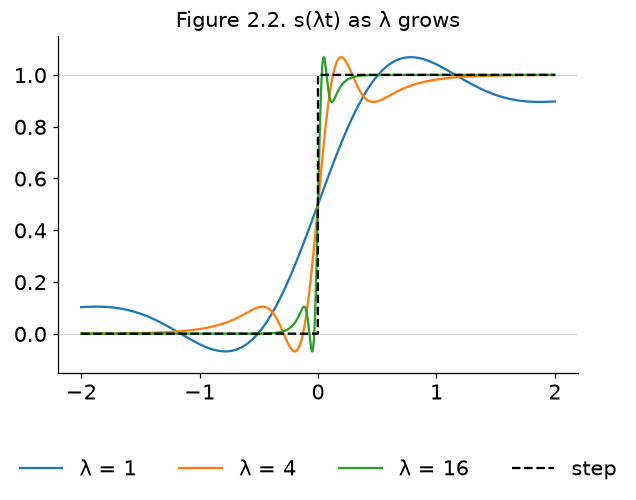

In [13]:
# c.2.3
# steepening: s2(λt) tends to the step except at t = 0; the
# overshoot keeps its height and moves into t = 0
# numeric copy of s that avoids underflow of exp(-t^2) for large t
def sNum(t):
    return logistic_sigmoid(t) + np.sin(t) * np.exp(-np.minimum(t**2, 700))

tq = np.linspace(-2, 2, 2001)
fig, ax = plt.subplots(figsize=(wFull, 0.65 * wFull))
for lam in (1, 4, 16):
    ax.plot(tq, sNum(lam * tq), label=f"λ = {lam}")
ax.plot(tq, unit_step(tq), "k--", label="step")
for lv in (0, 1):
    ax.axhline(lv, color="0.85", lw=0.8, zorder=0)
ax.set(ylim=(-0.15, 1.15), title="Figure 2.2. s(λt) as λ grows")
legend_below(ax, ncol=4)
plt.show()

### Does the staircase converge?

Build the staircase of Eq. (M7) from s instead of σ. Compared with the ideal staircase ${S}_{N}$ of Eq. (1.3), each step now has a wiggle of relative size up to 0.068 on either side. Splitting the error as in Problem 1 gives the bound

$$
\begin{gathered}| {G}_{N} ( x ) - f ( x ) | \le {\omega}_{f} ( \frac{1}{2 N} ) + {K}_{s} \  {\omega}_{f} ( \frac{1}{N} ) \\ {K}_{s} = \sup _{x} \  \sum_{k} | s ( \lambda ( x - {c}_{k} ) ) - H ( x - {c}_{k} ) |\end{gathered} \quad  \tag{2.2}
$$

The first term is the ideal staircase, Eq. (7.1) below. The second collects all the steps, each of height |${\Delta}_{k}$| ≤ ${\omega}_{f}$(1/N). With λ = c N the constant ${K}_{s}$ depends only on s and c, not on N, because |s(u) - H(u)| decays fast (here like ${e}^{-u}$). So the error is O(${\omega}_{f}$(1/N)), the same order as for the logistic. Only the constant changes.

*Figure 2.3. Left: ${G}_{10}$ for example A built from the logistic and from s, with a deliberately soft λ = 40 so that the wiggles are visible. Right: a zoom.*

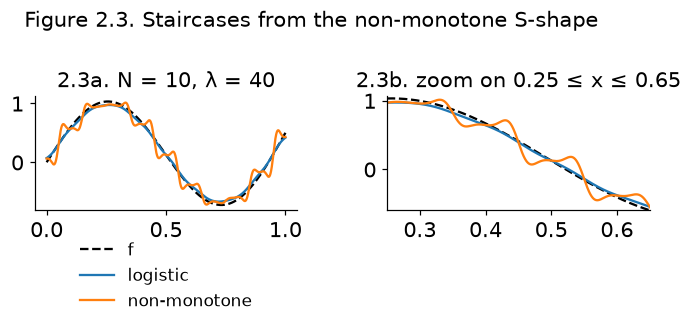

In [14]:
# c.2.4
# the same function, safe for whole arrays of large arguments
s2v = sNum
gS = stairOn(s2v, f(nodes(10)), 40, xsFine)
gL = stairOn(logistic_sigmoid, f(nodes(10)), 40, xsFine)
fig, axs = panels(1, 2, "Figure 2.3. Staircases from the non-monotone S-shape", h=1.0)
for j, ax in enumerate(axs[0]):
    ax.plot(xsFine, f(xsFine), "k--", label="f")
    ax.plot(xsFine, gL, label="logistic")
    ax.plot(xsFine, gS, label="non-monotone")
axs[0, 0].set_title("2.3a. N = 10, λ = 40")
legend_below(axs[0, 0], ncol=1, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.15))
mask = (xsFine >= 0.25) & (xsFine <= 0.65)
axs[0, 1].set(xlim=(0.25, 0.65), ylim=(min(gS[mask].min(), gL[mask].min()) - 0.05, max(gS[mask].max(), gL[mask].max()) + 0.05),
              xticks=[0.3, 0.4, 0.5, 0.6], title="2.3b. zoom on 0.25 ≤ x ≤ 0.65")
fig.tight_layout()
plt.show()

To test how much the wiggle matters, Table 2.2 uses the family σ(t) + A sin(t) exp(-${t}^{2}$) with amplitude A = 0 (the logistic), A = 1 (the function of the problem) and A = 3, which overshoots to 1.85 and -0.85.

*Table 2.2. Sup-norm error of ${G}_{N}$ for example A, λ = 20 N, three amplitudes A.*

In [15]:
# c.2.5
# the family σ + A sin(t) exp(-t²): A = 0 is the logistic
def sA(a):
    return lambda t: logistic_sigmoid(t) + a * np.sin(t) * np.exp(-np.minimum(t**2, 700))

nsA = [5, 10, 20, 40, 80, 160]
errA = {a: np.array([supErrS(sA(a), f, n, 20 * n) for n in nsA]) for a in (0, 1, 3)}
table([["A"] + [f"N = {n}" for n in nsA]] +
      [[a] + [nf(e, 3) for e in errA[a]] for a in (0, 1, 3)] +
      [["ratio A=1 / A=0"] + [nf(e, 3) for e in errA[1] / errA[0]]], "Table 2.2")

A,N = 5,N = 10,N = 20,N = 40,N = 80,N = 160
0,0.442,0.22,0.11,0.0551,0.0276,0.0138
1,0.714,0.377,0.191,0.096,0.0391,0.0195
3,1.6,0.915,0.466,0.233,0.0977,0.0489
ratio A=1 / A=0,1.62,1.71,1.73,1.74,1.42,1.42


**Table 2.2**

| A | N = 5 | N = 10 | N = 20 | N = 40 | N = 80 | N = 160 |
|---|---|---|---|---|---|---|
| 0 | 0.442 | 0.22 | 0.11 | 0.0551 | 0.0276 | 0.0138 |
| 1 | 0.714 | 0.377 | 0.191 | 0.096 | 0.0391 | 0.0195 |
| 3 | 1.6 | 0.915 | 0.466 | 0.233 | 0.0977 | 0.0489 |
| ratio A=1 / A=0 | 1.62 | 1.71 | 1.73 | 1.74 | 1.42 | 1.42 |

*Figure 2.4. The same errors on log-log axes. All three lines are parallel to slope -1 (dashed).*

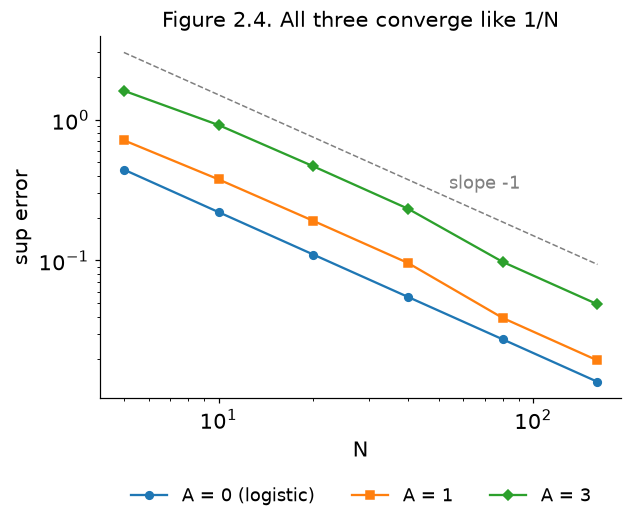

In [16]:
# c.2.6
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
for i, (a, lbl) in enumerate([(0, "A = 0 (logistic)"), (1, "A = 1"), (3, "A = 3")]):
    ax.loglog(nsA, errA[a], marker=mk[i], ms=5, label=lbl)
logLine(ax, [[5, 3.], [160, 3. / 32]])
logText(ax, "slope -1", (70, 0.35))
ax.set(xlabel="N", ylabel="sup error", title="Figure 2.4. All three converge like 1/N")
legend_below(ax, ncol=3, fontsize=figFont - 2)
plt.show()

### Answer

Yes, σ(t) + sin(t) exp(-${t}^{2}$) is sigmoidal: its limits are 0 and 1, and Eq. (M1) asks for nothing else. It is not monotone. It overshoots to 1.068 and -0.068. Yes, the staircase still converges, at the same rate O(1/N) as the logistic staircase, with an error about 1.4 to 1.7 times larger (Table 2.2). Even A = 3 converges. The reason is Eq. (2.2): every wiggle is scaled by a jump ${\Delta}_{k}$ of f, and the jumps shrink like ${\omega}_{f}$(1/N). This is the content of Cybenko's theorem, which asks for continuity and the two limits, and not for monotonicity.

## 3. Problem 3: the polynomial activation t²

**Problem 3.** Try the least-squares fit of section 5 (Table M4) with σ(t) = ${t}^{2}$, a polynomial. The error stops improving. Which of Theorems M1–M8 explains this?

### The experiment

Cells c.12–c.14 of the main notebook are repeated with the activation as a parameter: random inner weights ${y}_{j}$, ${\theta}_{j}$ in [-6, 6], least-squares outer weights ${\alpha}_{j}$, 2000 training and 2000 test points, target g(x, y) = sin(πx) cos(πy) on [-1, 1]². Besides ${t}^{2}$ we also try ${t}^{3}$.

*Table 3.1. Maximum and RMS test errors for N hidden units, three activations.*

In [17]:
# c.3.1
# section 5 of the main notebook (c.12-c.14), with the activation as
# a parameter. The pseudoinverse gives the least-squares α even when the
# columns of the hidden matrix are linearly dependent, as for t^2
def g(x, y):
    return np.sin(np.pi * x) * np.cos(np.pi * y)

rng = np.random.default_rng(3)
trainPts = rng.uniform(-1, 1, (2000, 2))
testPts = rng.uniform(-1, 1, (2000, 2))
def hiddenA(act):
    return lambda pts, Yin, th: act(pts @ Yin.T + th)

def fitA(act, nh):
    Yr = rng.uniform(-6, 6, (nh, 2))
    th = rng.uniform(-6, 6, nh)
    a = np.linalg.pinv(hiddenA(act)(trainPts, Yr, th)) @ g(*trainPts.T)
    return Yr, th, a

def testErr(act, nh):
    m = fitA(act, nh)
    r = hiddenA(act)(testPts, m[0], m[1]) @ m[2] - g(*testPts.T)
    return np.max(np.abs(r)), np.sqrt(np.mean(r**2))

acts = {"logistic": logistic_sigmoid, "t²": lambda t: t**2, "t³": lambda t: t**3}
nsQ = [2, 4, 6, 10, 20, 50, 100, 200]
rng = np.random.default_rng(7)
errQ = {k: np.array([testErr(act, nh) for nh in nsQ]) for k, act in acts.items()}
table([["N", "logistic max", "logistic RMS", "t² max", "t² RMS", "t³ max", "t³ RMS"]] +
      [[nh] + [nf(v, 3) for k in acts for v in errQ[k][i]] for i, nh in enumerate(nsQ)], "Table 3.1")

N,logistic max,logistic RMS,t² max,t² RMS,t³ max,t³ RMS
2,1.03,0.504,1.04,0.505,1.02,0.504
4,1.08,0.476,1.04,0.505,1.01,0.499
6,1.17,0.461,1.07,0.505,1.15,0.43
10,1.15,0.476,1.07,0.505,1.32,0.342
20,0.545,0.137,1.07,0.505,1.32,0.342
50,0.0425,0.0107,1.07,0.505,1.32,0.342
100,0.00536,0.000612,1.07,0.505,1.32,0.342
200,0.000365,0.0000209,1.07,0.505,1.32,0.342


**Table 3.1**

| N | logistic max | logistic RMS | t² max | t² RMS | t³ max | t³ RMS |
|---|---|---|---|---|---|---|
| 2 | 1.12 | 0.505 | 1.02 | 0.507 | 1.06 | 0.493 |
| 4 | 1.08 | 0.417 | 1.03 | 0.508 | 1.08 | 0.502 |
| 6 | 0.894 | 0.427 | 1.07 | 0.508 | 1.8 | 0.408 |
| 10 | 1.14 | 0.353 | 1.07 | 0.508 | 1.34 | 0.331 |
| 20 | 0.355 | 0.0898 | 1.07 | 0.508 | 1.34 | 0.331 |
| 50 | 0.118 | 0.0162 | 1.07 | 0.508 | 1.34 | 0.331 |
| 100 | 0.00832 | 0.0009 | 1.07 | 0.508 | 1.34 | 0.331 |
| 200 | 0.0003 | 0.0000175 | 1.07 | 0.508 | 1.34 | 0.331 |

The logistic error keeps falling, from 0.5 to 2 × ${10}^{-5}$ in RMS. The ${t}^{2}$ error is stuck at 0.505 from the start, and the ${t}^{3}$ error drops once, to 0.342, at N = 10, and then stops for good. Adding units does nothing.

### Why: the network is a polynomial

With σ(t) = ${t}^{2}$ every hidden unit is the square of an affine function, and expanding the square gives only the monomials 1, x, y, ${x}^{2}$, x y, ${y}^{2}$:

$$
\begin{gathered}{\sum}_{j = 1}^{N} {\alpha}_{j} \  {( {y}_{j 1} x + {y}_{j 2} y + {\theta}_{j} )}^{2} = {a}_{0} + {a}_{1} x + {a}_{2} y + {a}_{3} {x}^{2} + {a}_{4} x y + {a}_{5} {y}^{2}\end{gathered} \quad  \tag{3.1}
$$

However many units there are, the network is a polynomial of degree at most 2, an element of a 6-dimensional space. With ${t}^{3}$ it is a polynomial of degree at most 3. In general the polynomials of degree at most k in n variables form a space of dimension

$$
\dim  \  {P}_{k} ( {\mathbb{R}}^{n} ) = \begin{pmatrix}n + k \\ k\end{pmatrix} , n = 2 : k = 2 \implies 6 , k = 3 \implies 10 \quad  \tag{3.2}
$$

Adding units adds columns to the 2000 × N hidden matrix, but beyond 6 (or 10) columns they are linear combinations of the earlier ones. The rank stops growing, Table 3.3, and the singular values beyond the 6th (or 10th) are zero up to rounding, Figure 3.2. The least-squares fit can then do no better than the best polynomial of that degree. That polynomial can be computed exactly by projecting g onto the monomials in the mean square over [-1, 1]²:

$$
{p}_{2} = 0 , {p}_{3} = \frac{45 x ( 1 - 3 {y}^{2} )}{2 {\pi}^{3}} \quad  \tag{3.3}
$$

The best quadratic is zero. g is odd in x and even in y, so the only quadratic monomial that could match it is x, and its coefficient contains the integral of cos(πy) over [-1, 1], which is 0. The RMS error of the zero polynomial is the RMS of g itself, 1/2. The cubic picks up x and x ${y}^{2}$, and its error is 0.331. Both agree with the plateaus of Table 3.1; the small differences come from using 2000 sample points instead of the integral.

*Table 3.2. Best polynomial approximations of degree 2 and 3, their RMS errors, and the plateaus of Table 3.1.*

In [18]:
# c.3.2
# the best polynomial approximations of degree 2 and 3 in L²([-1,1]²),
# computed exactly by projection
x, y = sp.symbols("x y", real=True)
gSym = sp.sin(sp.pi * x) * sp.cos(sp.pi * y)
def integrate2(e):
    return sp.integrate(e, (x, -1, 1), (y, -1, 1))

def proj(basis):
    gram = sp.Matrix([[integrate2(a * b) for b in basis] for a in basis])
    rhs = sp.Matrix([integrate2(a * gSym) for a in basis])
    return sp.factor(sp.simplify((gram.LUsolve(rhs).T * sp.Matrix(basis))[0]))

def poly(k):
    return [x**i * y**j for i in range(k + 1) for j in range(k + 1 - i)]

best2, best3 = proj(poly(2)), proj(poly(3))
# exact RMS error over the square
def rmsOf(p):
    return float(sp.sqrt(integrate2(sp.expand((gSym - p)**2)) / 4))

table([["degree", "monomials", "best polynomial", "RMS error", "plateau of Table 3.1"],
       [2, len(poly(2)), pretty(best2), nf(rmsOf(best2), 4), nf(errQ["t²"][-1][1], 4)],
       [3, len(poly(3)), pretty(best3), nf(rmsOf(best3), 4), nf(errQ["t³"][-1][1], 4)]], "Table 3.2")

degree,monomials,best polynomial,RMS error,plateau of Table 3.1
2,6,0,0.5,0.5055
3,10,-45 x (3 y^2 - 1)/(2 π^3),0.331,0.3421


**Table 3.2**

| degree | monomials | best polynomial | RMS error | plateau of Table 3.1 |
|---|---|---|---|---|
| 2 | 6 | $0$ | 0.5 | 0.5083 |
| 3 | 10 | $\frac{45 x \left(1-3 y^2\right)}{2 \pi ^3}$ | 0.331 | 0.3311 |

*Figure 3.1. RMS test error against N. Dashed horizontal lines: the errors 0.5 and 0.331 of the best quadratic and cubic. Dashed vertical lines: N = 6 and N = 10, the dimensions of Eq. (3.2).*

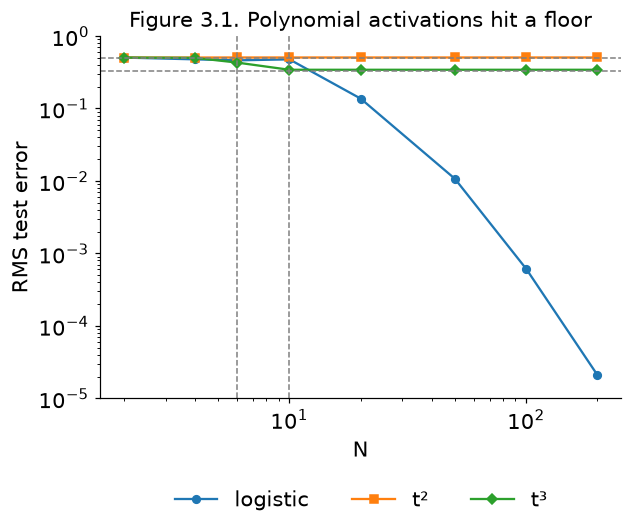

In [19]:
# c.3.3
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
for i, k in enumerate(acts):
    ax.loglog(nsQ, errQ[k][:, 1], marker=mk[i], ms=5, label=k)
for v in (6, 10):
    ax.axvline(v, color="gray", ls="--", lw=1)
for v in (rmsOf(best2), rmsOf(best3)):
    ax.axhline(v, color="gray", ls="--", lw=1)
ax.set(ylim=(1e-5, 1), xlabel="N", ylabel="RMS test error", title="Figure 3.1. Polynomial activations hit a floor")
legend_below(ax, ncol=3)
plt.show()

*Table 3.3. Rank of the hidden matrix. The logistic columns stay independent; the ${t}^{2}$ and ${t}^{3}$ columns saturate at 6 and 10.*

In [20]:
# c.3.4
# rank of the 2000 x N hidden matrix: t^2 and t^3 saturate at 6 and 10
rng = np.random.default_rng(5)
def rk(act, nh):
    m = hiddenA(act)(trainPts, rng.uniform(-6, 6, (nh, 2)), rng.uniform(-6, 6, nh))
    return np.linalg.matrix_rank(m, rtol=1e-9)   # drop singular values below 10^-9 of the largest

table([["N", "rank, logistic", "rank, t²", "rank, t³"]] +
      [[nh, rk(logistic_sigmoid, nh), rk(acts["t²"], nh), rk(acts["t³"], nh)] for nh in (4, 6, 8, 10, 20, 50)],
      "Table 3.3")

N,"rank, logistic","rank, t²","rank, t³"
4,4,4,4
6,6,6,6
8,8,6,8
10,10,6,10
20,20,6,10
50,50,6,10


**Table 3.3**

| N | rank, logistic | rank, t² | rank, t³ |
|---|---|---|---|
| 4 | 4 | 4 | 4 |
| 6 | 6 | 6 | 6 |
| 8 | 8 | 6 | 8 |
| 10 | 10 | 6 | 10 |
| 20 | 20 | 6 | 10 |
| 50 | 50 | 6 | 10 |

*Figure 3.2. Singular values of the hidden matrix for N = 40, relative to the largest. For ${t}^{2}$ and ${t}^{3}$ they collapse to rounding level after the 6th and the 10th.*

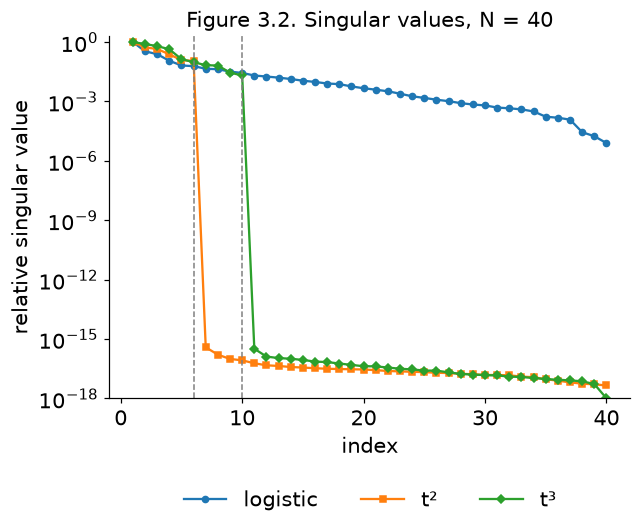

In [21]:
# c.3.5
rng = np.random.default_rng(5)
def svals(act):
    m = hiddenA(act)(trainPts, rng.uniform(-6, 6, (40, 2)), rng.uniform(-6, 6, 40))
    sv = np.linalg.svd(m, compute_uv=False)
    return sv / sv[0]

fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
for i, k in enumerate(acts):
    ax.semilogy(np.arange(1, 41), np.maximum(svals(acts[k]), 1e-18), marker=mk[i], ms=4, label=k)
for v in (6, 10):
    ax.axvline(v, color="gray", ls="--", lw=1)
ax.set(ylim=(1e-18, 2), xlabel="index", ylabel="relative singular value", title="Figure 3.2. Singular values, N = 40")
legend_below(ax, ncol=3)
plt.show()

*Figure 3.3. The target g and what the three networks learn with N = 200. The logistic network reproduces g; the ${t}^{2}$ network gives a nearly flat surface (the sampled best quadratic, close to 0); the ${t}^{3}$ network gives the cubic of Eq. (3.3).*

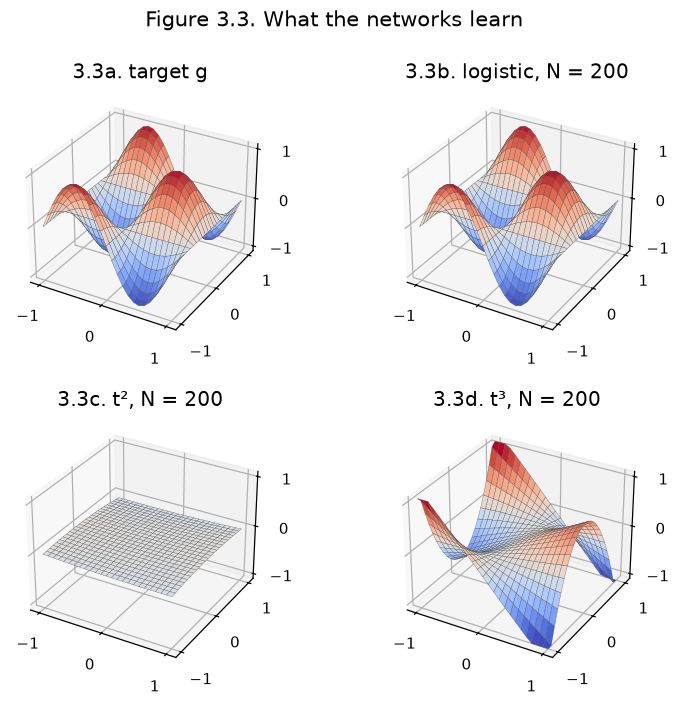

In [22]:
# c.3.6
rng = np.random.default_rng(8)
def netFun(act, nh):
    m = fitA(act, nh)
    return lambda X, Y: (hiddenA(act)(np.column_stack([X.ravel(), Y.ravel()]), m[0], m[1]) @ m[2]).reshape(X.shape)

fSq, fCu, fLo = netFun(acts["t²"], 200), netFun(acts["t³"], 200), netFun(logistic_sigmoid, 200)
gx, gy = np.meshgrid(np.linspace(-1, 1, 25), np.linspace(-1, 1, 25))
fig = plt.figure(figsize=(2 * wHalf + 1.2, 2 * wHalf + 0.6))
fig.suptitle("Figure 3.3. What the networks learn", fontsize=figFont)
for i, (fn, lbl) in enumerate([(g, "3.3a. target g"), (fLo, "3.3b. logistic, N = 200"),
                               (fSq, "3.3c. t², N = 200"), (fCu, "3.3d. t³, N = 200")]):
    ax = fig.add_subplot(2, 2, i + 1, projection="3d")
    ax.plot_surface(gx, gy, np.clip(fn(gx, gy), -1.1, 1.1), cmap="coolwarm", vmin=-1, vmax=1, lw=0.2, edgecolor="0.3")
    ax.set(zlim=(-1.1, 1.1), xticks=[-1, 0, 1], yticks=[-1, 0, 1], zticks=[-1, 0, 1])
    ax.set_title(lbl, fontsize=figFont - 1)
    ax.tick_params(labelsize=figFont - 4)
fig.tight_layout()
plt.show()

### Which theorem?

- Theorem M8 (Leshno, Lin, Pinkus and Schocken) explains it. One-hidden-layer networks are universal if and only if the activation is not a polynomial. Its "only if" direction is exactly Eq. (3.1): with a polynomial activation of degree k the network can only make polynomials of degree at most k, a finite-dimensional space, which cannot approximate every continuous function.
- Theorems M1–M4 of Cybenko do not apply, since ${t}^{2}$ is not sigmoidal: both its limits are +∞. But a theorem that does not apply says nothing about failure; Cybenko gives sufficient conditions only.
- Theorems M6 and M7 also do not apply (${t}^{2}$ is neither squashing nor bounded), and they too only give sufficient conditions. Only Theorem M8 is an "if and only if".

### Answer

With σ(t) = ${t}^{2}$ every network is a quadratic polynomial, Eq. (3.1), whatever N is. The least-squares error stops at that of the best quadratic, which for this g is the zero polynomial with RMS error 1/2. With ${t}^{3}$ it stops at the best cubic, RMS 0.331. Theorem M8 of Leshno, Lin, Pinkus and Schocken explains this: one hidden layer is universal exactly when the activation is not a polynomial.

## 4. Problem 4: x y z as a Kolmogorov superposition

**Problem 4.** Write x y z as a superposition in the form of Eq. (M8), using one-variable functions and addition, valid for positive x, y, z.

### The solution

The logarithm turns a product into a sum, and the exponential turns it back:

$$
x y z = \exp  ( \ln  \  x + \ln  \  y + \ln  \  z ) , x , y , z > 0 \quad  \tag{4.1}
$$

This has the shape of Eq. (M8) with n = 3: inner functions applied to each variable separately, their sum, then one outer function. Eq. (M8) has 2n + 1 = 7 branches, q = 0, ..., 6; we need only the first and set the outer function of the others to zero:

$$
{\Phi}_{0} = \exp  , {\psi}_{p , 0} = \ln  , {\Phi}_{q} = 0 \  for \  q = 1 , \ldots , 6 \quad  \tag{4.2}
$$

The inner functions are continuous and increasing, as in Kolmogorov's theorem, but they are not universal: they were chosen for this f. Kolmogorov's theorem promises universal inner functions that work for every f, at the price of being very rough. Here a smooth, special-purpose choice is enough. Positivity is needed because ln is defined only for positive arguments: at x = 0 the inner value would be -∞.

*Two checks: the identities used, symbolically.*

In [23]:
# c.4.1
# the two identities behind the solution
x, y, z = sp.symbols("x y z", positive=True)
xr, yr, zr = sp.symbols("x y z", real=True)
{"exp(ln x + ln y + ln z) = x y z, for x, y, z > 0":
     sp.simplify(sp.exp(sp.log(x) + sp.log(y) + sp.log(z)) - x * y * z) == 0,
 "four cubes, Eq. (4.3), for all real x, y, z":
     sp.expand(((xr + yr + zr)**3 - (xr + yr - zr)**3 - (xr - yr + zr)**3 + (xr - yr - zr)**3) / 24) == xr * yr * zr}

{'exp(ln x + ln y + ln z) = x y z, for x, y, z > 0': True,
 'four cubes, Eq. (4.3), for all real x, y, z': True}

*Eq. (M8) for n = 3 with the functions of Eq. (4.2), checked symbolically and on 10000 random points of (0, 1]³.*

In [24]:
# c.4.2
# Eq. (8) of the main notebook for n = 3: 2n + 1 = 7 branches,
# q = 0, ..., 6. Branch 0 carries the product, the others are zero
def psi(p, q, mod=np):   # inner functions ψ_{p,q}
    return mod.log if q == 0 else (lambda t: 0 * t)

def Phi(q, mod=np):      # outer functions Φ_q
    return mod.exp if q == 0 else (lambda s: 0 * s)

def kolmogorov(xs, mod=np):
    return sum(Phi(q, mod)(sum(psi(p, q, mod)(xs[p - 1]) for p in range(1, 4))) for q in range(7))

rng = np.random.default_rng(4)
pts = rng.uniform(0.001, 1, (10000, 3))
{"symbolic": sp.simplify(kolmogorov([x, y, z], sp) - x * y * z) == 0,
 "largest relative error on 10000 random points": np.max(np.abs(kolmogorov(pts.T) / np.prod(pts, axis=1) - 1))}

{'symbolic': True,
 'largest relative error on 10000 random points': np.float64(1.887379141862766e-15)}

*Figure 4.1. Eq. (M8) as a network for n = 3, in the style of Figure M8. All seven branches are drawn; only the branch q = 0 (black edges, red nodes) does any work, and the other six have outer function 0.*

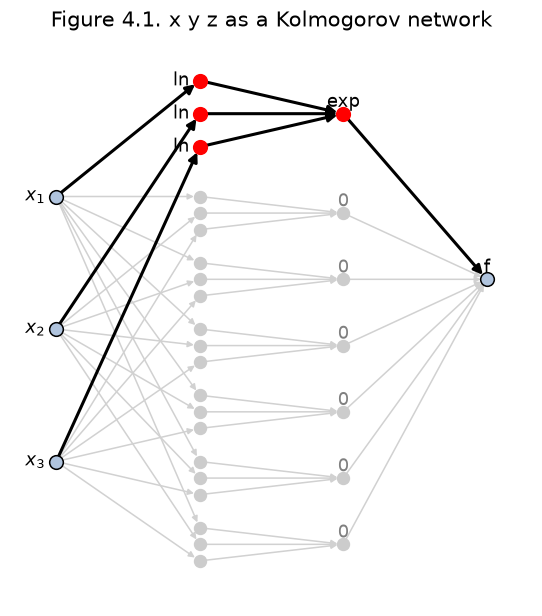

In [25]:
# c.4.3
# Eq. (8) drawn as a network for n = 3, in the style of Figure M8.
# Black and red: the branch q = 0 that does the work. Gray: the six
# branches whose outer function is zero
K3 = nx.DiGraph()
for p in (1, 2, 3):
    for q in range(7):
        K3.add_edge(f"x{p}", f"ψ{p}{q}")
        K3.add_edge(f"ψ{p}{q}", f"Φ{q}")
for q in range(7):
    K3.add_edge(f"Φ{q}", "f")
active = [(f"x{p}", f"ψ{p}0") for p in (1, 2, 3)] + [(f"ψ{p}0", "Φ0") for p in (1, 2, 3)] + [("Φ0", "f")]
# one row per inner function, grouped by branch q
def yPsi(p, q):
    return -2 * p if q == 0 else -(4 * q + p + 4)

pos = {f"ψ{p}{q}": (2, yPsi(p, q)) for p in (1, 2, 3) for q in range(7)}
pos |= {f"Φ{q}": (4, yPsi(2, q)) for q in range(7)}
pos |= {f"x{p}": (0, -(8 * p + 1)) for p in (1, 2, 3)} | {"f": (6, -14)}
red = [f"ψ{p}0" for p in (1, 2, 3)] + ["Φ0"]
labels = {"Φ0": "exp", "f": "f"}
fig, ax = plt.subplots(figsize=(wFull, 1.1 * wFull))
nx.draw_networkx_edges(K3, pos, edgelist=[e for e in K3.edges if e not in active], edge_color="0.82",
                       arrowsize=8, node_size=60, ax=ax)
nx.draw_networkx_edges(K3, pos, edgelist=active, edge_color="black", width=2, arrowsize=12, node_size=60, ax=ax)
nx.draw_networkx_nodes(K3, pos, nodelist=[v for v in K3 if v not in red and v[0] in "ψΦ"], node_color="0.8",
                       node_size=60, ax=ax)
nx.draw_networkx_nodes(K3, pos, nodelist=red, node_color="red", node_size=80, ax=ax)
nx.draw_networkx_nodes(K3, pos, nodelist=["x1", "x2", "x3", "f"], node_color="lightsteelblue", edgecolors="black",
                       node_size=80, ax=ax)
nx.draw_networkx_labels(K3, {v: (a, b + 0.7) for v, (a, b) in pos.items() if v in labels}, labels,
                        font_size=figFont - 2, ax=ax)
for p in (1, 2, 3):
    ax.text(-0.15, -(8 * p + 1), f"$x_{p}$", ha="right", va="center", fontsize=figFont - 2)
    ax.text(2 - 0.15, yPsi(p, 0), "ln", ha="right", va="center", fontsize=figFont - 2)
nx.draw_networkx_labels(K3, {f"Φ{q}": (4, yPsi(2, q) + 0.7) for q in range(1, 7)},
                        {f"Φ{q}": "0" for q in range(1, 7)}, font_size=figFont - 2, font_color="gray", ax=ax)
ax.set_title("Figure 4.1. x y z as a Kolmogorov network", fontsize=figFont)
ax.axis("off")
plt.show()

*Figure 4.2. The path of the input (0.5, 0.4, 0.8) through the network. Left: the inner function ln at the three inputs. Right: the outer function exp at their sum.*

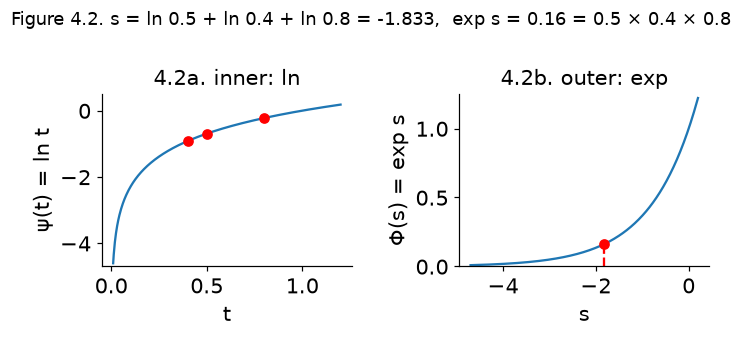

In [26]:
# c.4.4
# the path of one input, (x, y, z) = (0.5, 0.4, 0.8), through the
# network: three inner values, one sum, one outer value
pt = np.array([0.5, 0.4, 0.8])
sPt = np.sum(np.log(pt))
fig, axs = panels(1, 2, f"Figure 4.2. s = ln 0.5 + ln 0.4 + ln 0.8 = {nf(sPt, 4)},  exp s = {nf(np.exp(sPt), 4)}"
                  " = 0.5 × 0.4 × 0.8", h=0.95)
a1, a2 = axs[0]
tl = np.linspace(0.01, 1.2, 400)
a1.plot(tl, np.log(tl))
a1.plot(pt, np.log(pt), "o", color="red")
a1.set(ylim=(-4.7, 0.5), xlabel="t", ylabel="ψ(t) = ln t", title="4.2a. inner: ln")
se = np.linspace(-4.7, 0.2, 400)
a2.plot(se, np.exp(se))
a2.plot([sPt, sPt], [0, np.exp(sPt)], "r--")
a2.plot(sPt, np.exp(sPt), "o", color="red")
a2.set(ylim=(0, 1.25), xlabel="s", ylabel="Φ(s) = exp s", title="4.2b. outer: exp")
fig.suptitle(fig.get_suptitle(), fontsize=figFont - 2)
fig.tight_layout()
plt.show()

Geometrically the inner functions straighten the function. The level sets x y z = c are curved surfaces, but in the coordinates (ln x, ln y, ln z) they become the parallel planes u + v + w = ln c. After the inner functions, the function depends only on the sum of the coordinates, which is exactly what Eq. (M8) demands of each branch.

*Figure 4.3. Left: the level sets x y z = 0.02, 0.1, 0.3. Right: the same sets after the inner functions, flat parallel planes.*

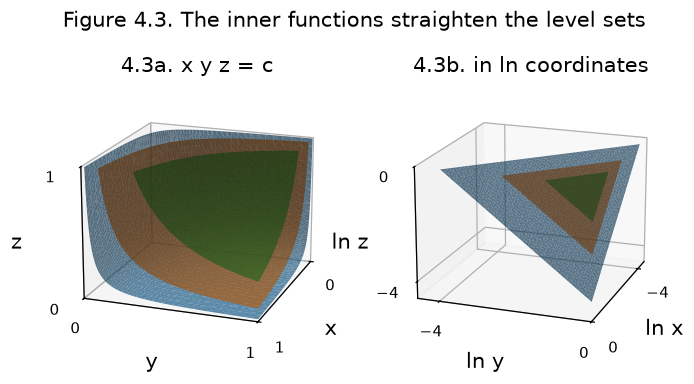

In [27]:
# c.4.5
# level sets: x y z = c is curved; in the coordinates of the inner
# functions, (ln x, ln y, ln z), it is the flat plane u + v + w = ln c
levels = [0.02, 0.1, 0.3]
fig = plt.figure(figsize=(2 * wHalf + 1.2, 1.15 * wHalf))
fig.suptitle("Figure 4.3. The inner functions straighten the level sets", fontsize=figFont, y=1.05)
a1 = fig.add_subplot(1, 2, 1, projection="3d")
a2 = fig.add_subplot(1, 2, 2, projection="3d")
# inside the unit cube both sets are triangles in ln coordinates:
# (ln x, ln y, ln z) = ln c (a, b, 1 - a - b) with a, b >= 0, a + b <= 1
from matplotlib.tri import Triangulation
A, B = np.meshgrid(np.linspace(0, 1, 61), np.linspace(0, 1, 61))
keep = A + B <= 1 + 1e-12
A, B = A[keep], B[keep]
tri = Triangulation(A, B)
for i, c in enumerate(levels):
    lu, lv, lw = np.log(c) * A, np.log(c) * B, np.log(c) * (1 - A - B)
    a1.plot_trisurf(np.exp(lu), np.exp(lv), np.exp(lw), triangles=tri.triangles, color=C[i], alpha=0.7, lw=0)
    a2.plot_trisurf(lu, lv, lw, triangles=tri.triangles, color=C[i], alpha=0.7, lw=0)
a1.set(xlim=(0, 1), ylim=(0, 1), zlim=(0, 1), xticks=[0, 1], yticks=[0, 1], zticks=[0, 1],
       xlabel="x", ylabel="y", zlabel="z", title="4.3a. x y z = c")
a2.set(xlim=(-4.6, 0), ylim=(-4.6, 0), zlim=(-4.6, 0), xticks=[-4, 0], yticks=[-4, 0], zticks=[-4, 0],
       xlabel="ln x", ylabel="ln y", zlabel="ln z", title="4.3b. in ln coordinates")
for a in (a1, a2):
    a.view_init(elev=18, azim=20)
    a.tick_params(labelsize=figFont - 4)
plt.show()

### A version without positivity

Using cubes instead of the logarithm gives a superposition valid for all real x, y, z, zeros and negatives included:

$$
x y z = \frac{1}{24} [ {( x + y + z )}^{3} - {( x + y - z )}^{3} - {( x - y + z )}^{3} + {( x - y - z )}^{3} ] \quad  \tag{4.3}
$$

It uses four branches of Eq. (M8), with linear inner functions ±x, ±y, ±z and the outer functions ±s³/24. Since the inner functions are linear, this is also a network of the Cybenko form, Eq. (M3), with activation ${t}^{3}$ and four units. It is exact for this one product, while Problem 3 shows that the same activation cannot approximate functions in general. In the same way, the identity x y = ((x + y)^2 - (x - y)^2)/4 of c.16 in the main notebook is a two-branch superposition of the product of two variables.

*The four-cube identity on 10000 random points of [-1, 1]³, and at a point with a zero coordinate.*

In [28]:
# c.4.6
# the four-cube form of Eq. (4.3) on [-1, 1]³, zeros included:
# four branches with linear inner functions ±x and one outer
# function Φ(s) = ± s³/24
def cubeBranches(x, y, z):
    return np.array([(x + y + z)**3, -(x + y - z)**3, -(x - y + z)**3, (x - y - z)**3]) / 24

rng = np.random.default_rng(6)
pts3 = rng.uniform(-1, 1, (10000, 3))
{"largest error on 10000 points of [-1, 1]³":
     np.max(np.abs(cubeBranches(*pts3.T).sum(axis=0) - np.prod(pts3, axis=1))),
 "at a point with a zero coordinate": cubeBranches(0., 0.7, -0.3).sum()}

{'largest error on 10000 points of [-1, 1]³': np.float64(4.440892098500626e-16),
 'at a point with a zero coordinate': np.float64(-1.734723475976807e-18)}

### Answer

For positive x, y, z: x y z = exp(ln x + ln y + ln z), Eq. (4.1). In the form of Eq. (M8) with n = 3 this is the branch q = 0 with ${\psi}_{p,0}$ = ln and ${\Phi}_{0}$ = exp; the other six branches have ${\Phi}_{q}$ = 0, Eq. (4.2). For all real inputs, the four-cube identity Eq. (4.3) does the same with linear inner functions.

## 5. Problem 5: BasicRecurrentLayer as a Cybenko sum

**Problem 5.** Show that one step of BasicRecurrentLayer, tanh(W x + U h + b), is a Cybenko-type sum when you take (x, h) as the input. Draw its graph in the style of Figure M3. Which arrow would you add to make it recurrent?

### One step is a Cybenko sum

BasicRecurrentLayer with input size n and state size m computes, at each time t,

$$
{h}_{t} = \tanh  ( W \  {x}_{t} + U \  {h}_{t - 1} + b ) \quad  \tag{5.1}
$$

with an m × n matrix W, an m × m matrix U and a bias vector b. Two facts turn this into Eq. (M3). First, tanh is a rescaled logistic, tanh s = 2σ(2s) - 1, Eq. (M2). Second, a constant is itself a hidden unit: -1 = -2σ(0·z + 0). Join the input and the old state into one vector z = (${x}_{t}$, ${h}_{t-1}$) of length n + m. Then component i of the new state is

$$
\begin{gathered}{h}_{t , i} = 2 \sigma ( 2 ( \sum_{k} {W}_{ik} {x}_{t , k} + \sum_{l} {U}_{il} {h}_{t - 1 , l} + {b}_{i} ) ) - 2 \sigma ( 0 ) \\ = \sum_{j} {\alpha}_{ij} \  \sigma ( {y}_{j} \cdot z + {\theta}_{j} ) , z = ( {x}_{t} , {h}_{t - 1} ) \in {\mathbb{R}}^{n + m}\end{gathered} \quad  \tag{5.2}
$$

Each component is a sum of Eq. (M3) on the cube of inputs z. It uses two units: unit i, with inner weights ${y}_{i}$ = 2(row i of W, row i of U), offset ${\theta}_{i}$ = 2${b}_{i}$ and outer weight 2, and a constant unit with y = 0, θ = 0 and outer weight -2. The whole new state is such a sum for each i, with the same hidden units shared and the outer weights ${\alpha}_{ij}$ = 2${\delta}_{ij}$. The step is a one-hidden-layer network in which the hidden layer and the output layer have the same size m. So by Theorem M2 a single step can be approximated in the other direction too: with enough units, a sum of this form can follow any continuous update rule for the state.

*Both facts, checked symbolically.*

In [29]:
# c.5.1
# the two facts used in Eq. (5.2): tanh is a rescaled logistic, and a
# constant is itself one hidden unit with zero input weights
s = sp.symbols("s", real=True)
sigma = lambda e: 1 / (1 + sp.exp(-e))
{"tanh s - (2 σ(2 s) - 1)": sp.simplify((sp.tanh(s) - (2 * sigma(2 * s) - 1)).rewrite(sp.exp)),
 "-1 = -2 σ(0 · z + 0)": -1 == -2 * sigma(0)}

{'tanh s - (2 σ(2 s) - 1)': 0, '-1 = -2 σ(0 · z + 0)': True}

A numerical check against a real layer. PyTorch's `nn.RNN` with tanh computes the same step as BasicRecurrentLayer, with two bias vectors that are added; one is set to nonzero values and the other to zero, so that b is a single vector as in Eq. (5.1). The layer is initialized with random weights and run on a sequence of 40 inputs in three ways: by the layer itself, by the tanh recursion Eq. (5.1), and by the Cybenko sums Eq. (5.2).

*Table 5.1. The weights of the layer and the agreement of the three computations. The layer computes in single precision, so it agrees with the other two to about ${10}^{-7}$; the tanh recursion and the Cybenko sums agree to ${10}^{-16}$.*

In [30]:
# c.5.2
# a real recurrent layer, PyTorch's nn.RNN with tanh, input size n = 2 and
# state size m = 2; its weights, then three ways to run it on the same sequence
import torch

torch.manual_seed(5)
rnn = torch.nn.RNN(input_size=2, hidden_size=2, nonlinearity="tanh", batch_first=True)
# nn.RNN has two bias vectors, b_ih + b_hh; use one bias b = (0.3, -0.4) as BasicRecurrentLayer does
with torch.no_grad():
    rnn.bias_ih_l0.copy_(torch.tensor([0.3, -0.4]))
    rnn.bias_hh_l0.zero_()
W, U, b = (rnn.weight_ih_l0.detach().double().numpy(), rnn.weight_hh_l0.detach().double().numpy(),
           rnn.bias_ih_l0.detach().double().numpy())
seq = np.array([[np.sin(t / 3.), np.cos(t / 5.)] for t in range(1, 41)])
# 1: the layer itself (single precision)
with torch.no_grad():
    hLayer = rnn(torch.tensor(seq[None], dtype=torch.float32))[0][0].double().numpy()
# 2: the recursion h_t = tanh(W x_t + U h_{t-1} + b), h_0 = 0
def run(step):
    h, out = np.zeros(2), []
    for xt in seq:
        h = step(h, xt)
        out.append(h)
    return np.array(out)

hTanh = run(lambda h, x: np.tanh(W @ x + U @ h + b))
# 3: the same step as a Cybenko sum of Eq. (5.2), input z = (x, h)
Yc = 2 * np.hstack([W, U])
thc = 2 * b
def cybenkoStep(h, x):
    zz = np.concatenate([x, h])
    return 2 * logistic_sigmoid(Yc @ zz + thc) - 2 * logistic_sigmoid(0. * (Yc @ zz))

hCyb = run(cybenkoStep)
table([["quantity", "value"],
       ["W (input weights)", mat(W)],
       ["U (state weights)", mat(U)],
       ["b (biases)", mat(b)],
       ["max |layer - tanh recursion|", sci(np.max(np.abs(hLayer - hTanh)))],
       ["max |layer - Cybenko sums|", sci(np.max(np.abs(hLayer - hCyb)))],
       ["max |tanh recursion - Cybenko sums|", sci(np.max(np.abs(hTanh - hCyb)))]], "Table 5.1")

quantity,value
W (input weights),"[[0.467, -0.529], [0.576, 0.452]]"
U (state weights),"[[0.594, -0.542], [-0.475, 0.336]]"
b (biases),"[0.3, -0.4]"
max |layer - tanh recursion|,8.6 × 10-8
max |layer - Cybenko sums|,8.6 × 10-8
max |tanh recursion - Cybenko sums|,2.2 × 10-16


**Table 5.1**

| quantity | value |
|---|---|
| W (input weights) | [[2.45, 1.06], [0.101, -0.02]] |
| U (state weights) | [[0.536, -1.15], [1.53, -0.284]] |
| b (biases) | [0.3, -0.4] |
| max \|layer - tanh recursion\| | 1.5 × 10<sup>-7</sup> |
| max \|layer - Cybenko sums\| | 1.5 × 10<sup>-7</sup> |
| max \|tanh recursion - Cybenko sums\| | 4.4 × 10<sup>-16</sup> |

### The graph

*Figure 5.1. One step of BasicRecurrentLayer drawn like Figure M3, for n = m = 2. The four inputs on the left are the components of z = (x, ${h}_{old}$). The red labels are the weights: 2${W}_{ik}$ and 2${U}_{il}$ on the arrows into the hidden units, 2 on the arrows out. The offsets 2${b}_{i}$ and the constant unit giving -1 are not drawn, as ${\theta}_{j}$ is not drawn in Figure M3.*

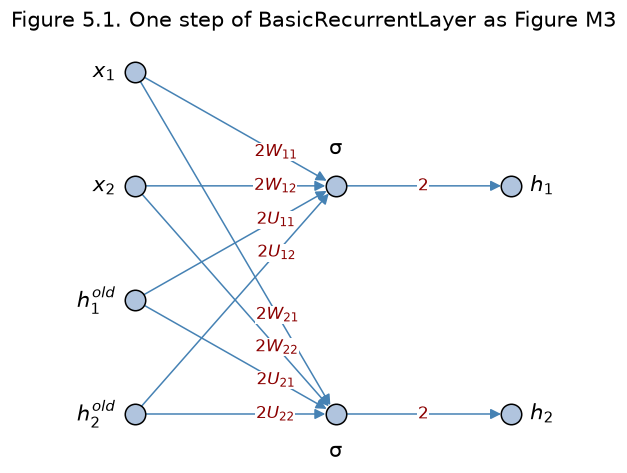

In [31]:
# c.5.3
# one step drawn like Figure M3: the input of the step is z = (x, h_old),
# four numbers; unit i computes σ(2 (W x + U h_old + b)_i), the output
# h_i = 2 (unit i) - 1. Offsets and the constant -1 are not drawn
ins = ["x1", "x2", "o1", "o2"]
insLbl = ["$x_1$", "$x_2$", "$h_1^{old}$", "$h_2^{old}$"]
def wLbl(i, k):
    return f"$2W_{{{i}{k}}}$" if k <= 2 else f"$2U_{{{i}{k - 2}}}$"

S1 = nx.DiGraph()
e1 = [(ins[k - 1], f"u{i}") for k in range(1, 5) for i in (1, 2)]
e2 = [(f"u{i}", f"h{i}") for i in (1, 2)]
S1.add_edges_from(e1 + e2)
pos = {ins[k - 1]: (0, 4.5 - 1.5 * k) for k in range(1, 5)} | {"u1": (3.2, 1.5), "u2": (3.2, -1.5),
                                                              "h1": (6, 1.5), "h2": (6, -1.5)}
fig, ax = plt.subplots(figsize=(wFull, 0.8 * wFull))
nx.draw_networkx_nodes(S1, pos, node_size=180, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_edges(S1, pos, node_size=180, arrowsize=14, edge_color="steelblue", ax=ax)
for v, lbl in zip(ins, insLbl):
    ax.text(pos[v][0] - 0.3, pos[v][1], lbl, ha="right", va="center", fontsize=figFont)
ax.text(3.2, 1.5 + 0.35, "σ", ha="center", va="bottom", fontsize=figFont)
ax.text(3.2, -1.5 - 0.35, "σ", ha="center", va="top", fontsize=figFont)
for i in (1, 2):
    ax.text(6.3, pos[f"h{i}"][1], f"$h_{i}$", ha="left", va="center", fontsize=figFont)
lab = dict(rotate=False, font_color="darkred", font_size=figFont - 3, bbox=dict(fc="white", ec="none", pad=0.3), ax=ax)
nx.draw_networkx_edge_labels(S1, pos, {(ins[k - 1], f"u{i}"): wLbl(i, k) for k in range(1, 5) for i in (1, 2)},
                             label_pos=0.72, **lab)
nx.draw_networkx_edge_labels(S1, pos, {e: "2" for e in e2}, label_pos=0.5, **lab)
ax.set_title("Figure 5.1. One step of BasicRecurrentLayer as Figure M3", fontsize=figFont)
ax.set_xlim(-1.3, 7)
ax.axis("off")
plt.show()

Read Figure 5.1 as Figure M3 was read in the main notebook. Information flows from left to right, each arrow multiplies by its weight, each hidden node adds what arrives and passes it through σ, and the arrows form a directed acyclic graph. Nothing in the picture is recurrent yet: ${h}_{old}$ is just two more inputs.

### The arrow that makes it recurrent

The recurrence is the identification of ${h}_{old}$ at time t with the output h at time t - 1. In the graph this means an arrow from each output node ${h}_{l}$ back to the state units, carrying the weight ${U}_{il}$ and crossed with a delay of one time step. These are the dashed blue arrows of Figure 5.2, including the self-loops ${U}_{11}$ and ${U}_{22}$. They make the graph cyclic, and this cycle is all that separates a recurrent layer from a feedforward one.

*Figure 5.2. The recurrent layer folded into one picture. Black arrows: the input weights ${W}_{ik}$, as in Figure 5.1. Dashed blue arrows: the new arrows ${U}_{il}$ from the state back into the state, each crossed one time step later.*

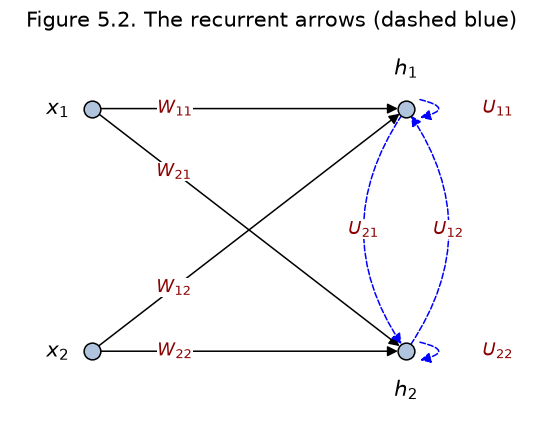

In [32]:
# c.5.4
# the recurrent layer: the new arrows U_il run from the state units back
# into the state units, and each is crossed one time step later
R = nx.DiGraph()
inE = [(f"x{k}", f"h{i}") for k in (1, 2) for i in (1, 2)]
recE = [(f"h{l}", f"h{i}") for l in (1, 2) for i in (1, 2)]
R.add_edges_from(inE + recE)
pos = {"x1": (0, 1.5), "x2": (0, -1.5), "h1": (3.5, 1.5), "h2": (3.5, -1.5)}
fig, ax = plt.subplots(figsize=(wFull, 0.75 * wFull))
nx.draw_networkx_nodes(R, pos, node_size=120, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_edges(R, pos, edgelist=inE, node_size=120, arrowsize=14, edge_color="black", ax=ax)
cross = [("h1", "h2"), ("h2", "h1")]
nx.draw_networkx_edges(R, pos, edgelist=cross, node_size=120, arrowsize=14, edge_color="blue", style="--",
                       connectionstyle="arc3,rad=0.35", ax=ax)
lab = dict(rotate=False, font_color="darkred", font_size=figFont - 2, bbox=dict(fc="white", ec="none", pad=0.3), ax=ax)
nx.draw_networkx_edge_labels(R, pos, {(f"x{k}", f"h{i}"): f"$W_{{{i}{k}}}$" for k in (1, 2) for i in (1, 2)},
                             label_pos=0.25, **lab)
nx.draw_networkx_edge_labels(R, pos, {(l, i): f"$U_{{{i[1]}{l[1]}}}$" for l, i in cross},
                             connectionstyle="arc3,rad=0.35", label_pos=0.5, **lab)
# self-loops U_11 and U_22, drawn by hand to the right of each state unit
from matplotlib.patches import FancyArrowPatch
for i, yc in ((1, 1.5), (2, -1.5)):
    ax.add_patch(FancyArrowPatch((3.62, yc + 0.12), (3.62, yc - 0.12), connectionstyle="arc3,rad=-2.2",
                                 arrowstyle="-|>", mutation_scale=14, color="blue", ls="--", lw=1))
    ax.text(4.35, yc, f"$U_{{{i}{i}}}$", color="darkred", fontsize=figFont - 2, va="center")
ax.text(-0.25, 1.5, "$x_1$", ha="right", va="center", fontsize=figFont)
ax.text(-0.25, -1.5, "$x_2$", ha="right", va="center", fontsize=figFont)
ax.text(3.5, 1.85, "$h_1$", ha="center", va="bottom", fontsize=figFont)
ax.text(3.5, -1.85, "$h_2$", ha="center", va="top", fontsize=figFont)
ax.set(xlim=(-0.9, 4.9), ylim=(-2.4, 2.4))
ax.set_title("Figure 5.2. The recurrent arrows (dashed blue)", fontsize=figFont)
ax.axis("off")
plt.show()

Unrolling removes the cycle again. Following the blue arrows forward in time gives a chain of copies of the same step, a deep feedforward network whose layers all share W, U and b:

$$
{h}_{t} = F ( {x}_{t} , {h}_{t - 1} ) = F ( {x}_{t} , F ( {x}_{t - 1} , F ( \ldots ) ) ) \quad  \tag{5.3}
$$

*Figure 5.3. The recurrent layer unrolled over four time steps. Each blue arrow is a copy of the step of Figure 5.1; backpropagation through time follows these arrows backwards, as Eq. (M5) follows the arrows of Figure M3.*

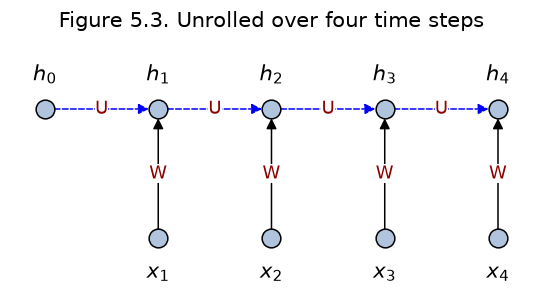

In [33]:
# c.5.5
# unrolled in time the loop disappears: a deep feedforward network in
# which every layer is the same Cybenko-type step, with shared W, U, b
T = 4
xE = [(f"x{t}", f"h{t}") for t in range(1, T + 1)]
hE = [(f"h{t - 1}", f"h{t}") for t in range(1, T + 1)]
Un = nx.DiGraph(xE + hE)
pos = {f"h{t}": (2 * t, 0) for t in range(T + 1)} | {f"x{t}": (2 * t, -1.6) for t in range(1, T + 1)}
fig, ax = plt.subplots(figsize=(wFull, 0.5 * wFull))
nx.draw_networkx_nodes(Un, pos, node_size=150, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_edges(Un, pos, edgelist=xE, node_size=150, arrowsize=14, edge_color="black", ax=ax)
nx.draw_networkx_edges(Un, pos, edgelist=hE, node_size=150, arrowsize=14, edge_color="blue", style="--", ax=ax)
nx.draw_networkx_labels(Un, {v: (a, b + 0.42 if v[0] == "h" else b - 0.42) for v, (a, b) in pos.items()},
                        {v: f"${v[0]}_{v[1]}$" for v in Un}, font_size=figFont, ax=ax)
lab = dict(rotate=False, font_color="darkred", font_size=figFont - 2, bbox=dict(fc="white", ec="none", pad=0.3), ax=ax)
nx.draw_networkx_edge_labels(Un, pos, {e: "W" for e in xE}, **lab)
nx.draw_networkx_edge_labels(Un, pos, {e: "U" for e in hE}, **lab)
ax.set_title("Figure 5.3. Unrolled over four time steps", fontsize=figFont)
ax.set(xlim=(-0.6, 2 * T + 0.6), ylim=(-2.3, 0.9))
ax.axis("off")
plt.show()

*Figure 5.4. The two state components over 40 time steps: the layer (points) and the Cybenko sums of Eq. (5.2) (line).*

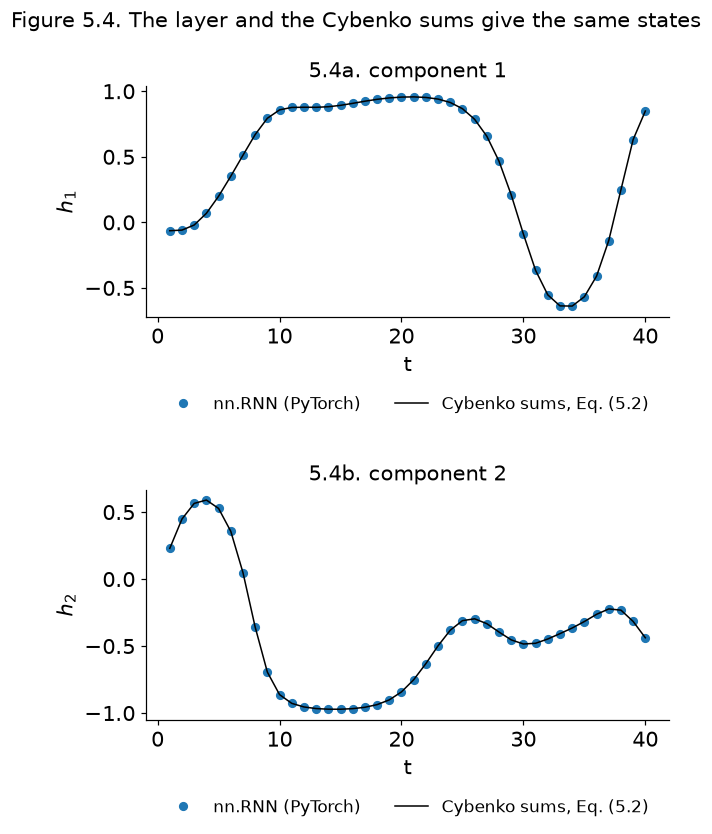

In [34]:
# c.5.6
fig, axs = plt.subplots(2, 1, figsize=(wFull, 1.3 * wFull))
fig.suptitle("Figure 5.4. The layer and the Cybenko sums give the same states", fontsize=figFont)
ts = np.arange(1, 41)
for i, ax in enumerate(axs):
    ax.plot(ts, hLayer[:, i], "o", ms=5, color=C[0], label="nn.RNN (PyTorch)")
    ax.plot(ts, hCyb[:, i], "k-", lw=1, label="Cybenko sums, Eq. (5.2)")
    ax.set(xlabel="t", ylabel=f"$h_{i + 1}$", title=f"5.4{'ab'[i]}. component {i + 1}")
    legend_below(ax, ncol=2, fontsize=figFont - 3, bbox_to_anchor=(0.5, -0.28))
fig.tight_layout()
plt.show()

### Answer

With z = (x, h) as the input, component i of tanh(W x + U h + b) equals 2σ(${y}_{i}$·z + ${\theta}_{i}$) - 2σ(0·z + 0) with ${y}_{i}$ = 2(${W}_{i}$, ${U}_{i}$) and ${\theta}_{i}$ = 2${b}_{i}$, a sum of Eq. (M3), Eq. (5.2). Figure 5.1 draws it in the style of Figure M3, and Table 5.1 confirms it against a real layer, PyTorch's `nn.RNN`, which computes the same step as BasicRecurrentLayer. To make it recurrent, add arrows from each state output ${h}_{l}$ back into each state unit ${h}_{i}$, carrying ${U}_{il}$ with a one-step delay (Figure 5.2).

## 6. Problem 6: the gradient with respect to the weights

**Problem 6.** Use Eq. (M5) to write ∂G/∂${\alpha}_{j}$ and ∂G/∂${y}_{ji}$, and check both against SymPy's `diff` as in c.7.

### The path rule for weights

Eq. (M5) gives the derivative of G with respect to an input as a sum, over all paths from that input to G, of the product of the local derivatives along the path. The same rule works for a weight. A weight sits on one arrow, so the paths start at that arrow. The derivative is the value at the tail of the arrow times the product of the local derivatives from its head to G. With ${z}_{j}$ = ${y}_{j}$·x + ${\theta}_{j}$ and ${h}_{j}$ = σ(${z}_{j}$), as in Eq. (M4):

- ${\alpha}_{j}$ sits on the arrow ${h}_{j}$ → G. Its tail carries ${h}_{j}$ = σ(${z}_{j}$), and the head is G itself:

$$
\frac{\partial G}{\partial {\alpha}_{j}} = \sigma ( {z}_{j} ) \quad  \tag{6.1}
$$

- ${\theta}_{j}$ is the weight of an arrow from a constant input 1 to ${h}_{j}$. Its tail carries 1; from there the path passes through the node ${h}_{j}$ (factor σ′(${z}_{j}$)) and the arrow ${h}_{j}$ → G (factor ${\alpha}_{j}$):

$$
\frac{\partial G}{\partial {\theta}_{j}} = {\alpha}_{j} \  {\sigma}^{\prime} ( {z}_{j} ) \quad  \tag{6.2}
$$

- ${y}_{ji}$ sits on the arrow ${x}_{i}$ → ${h}_{j}$. Its tail carries ${x}_{i}$, and the path continues exactly as for ${\theta}_{j}$:

$$
\frac{\partial G}{\partial {y}_{ji}} = {\alpha}_{j} \  {\sigma}^{\prime} ( {z}_{j} ) \  {x}_{i} \quad  \tag{6.3}
$$

Each weight lies on exactly one path to G, so each sum in Eq. (M5) has a single term. Eq. (6.3) is Eq. (6.2) times the input ${x}_{i}$. That is the familiar rule of backpropagation: the gradient of a weight is the signal flowing back to its head, ${\alpha}_{j}$ σ′(${z}_{j}$), times the activity at its tail.

*Table 6.1. The three formulas against SymPy's exact derivatives, for the random network of c.7 of the main notebook at the point x = (0.3, -0.7). Rows of the y matrix are the units j, columns the inputs i.*

In [35]:
# c.6.1
# Eqs. (6.1)-(6.3) against SymPy's exact derivatives, for the same
# random network as c.7 of the main notebook (n = 2, N = 3)
def gradient_table():
    rng = np.random.default_rng(2)
    Yw = rng.uniform(-2, 2, (3, 2))   # weights y_ji
    th = rng.uniform(-1, 1, 3)        # offsets θ_j
    al = rng.uniform(-1, 1, 3)        # output weights α_j
    x0 = np.array([0.3, -0.7])
    # symbolic parameters, so that SymPy can differentiate by them
    yv = sp.Matrix(3, 2, lambda j, i: sp.Symbol(f"y{j}{i}"))
    tv = sp.Matrix(3, 1, lambda j, _: sp.Symbol(f"t{j}"))
    av = sp.Matrix(3, 1, lambda j, _: sp.Symbol(f"a{j}"))
    zv = yv * sp.Matrix(x0) + tv
    gNet = sum(av[j] / (1 + sp.exp(-zv[j])) for j in range(3))
    rules = {**{yv[j, i]: Yw[j, i] for j in range(3) for i in range(2)},
             **{tv[j]: th[j] for j in range(3)}, **{av[j]: al[j] for j in range(3)}}
    auto = [np.array([float(sp.diff(gNet, av[j]).subs(rules)) for j in range(3)]),
            np.array([float(sp.diff(gNet, tv[j]).subs(rules)) for j in range(3)]),
            np.array([[float(sp.diff(gNet, yv[j, i]).subs(rules)) for i in range(2)] for j in range(3)])]
    # the path products of Eqs. (6.1)-(6.3)
    z = Yw @ x0 + th
    sp_ = logistic_sigmoid(z) * (1 - logistic_sigmoid(z))   # σ'(z_j)
    path = [logistic_sigmoid(z), al * sp_, np.outer(al * sp_, x0)]
    names = ["∂G/∂αⱼ, Eq. (6.1)", "∂G/∂θⱼ, Eq. (6.2)", "∂G/∂yⱼᵢ, Eq. (6.3)"]
    table([["derivative", "SymPy diff (exact)", "path product", "difference"]] +
          [[nm, mat(a, 4), mat(p, 4), sci(np.max(np.abs(a - p)))] for nm, a, p in zip(names, auto, path)],
          "Table 6.1")

gradient_table()

derivative,SymPy diff (exact),path product,difference
"∂G/∂αⱼ, Eq. (6.1)","[0.4143, 0.6525, 0.2749]","[0.4143, 0.6525, 0.2749]",0
"∂G/∂θⱼ, Eq. (6.2)","[0.07641, 0.02824, -0.1395]","[0.07641, 0.02824, -0.1395]",2.8 × 10-17
"∂G/∂yⱼᵢ, Eq. (6.3)","[[0.02292, -0.05348], [0.008471, -0.01977], [-0.04185, 0.09765]]","[[0.02292, -0.05348], [0.008471, -0.01977], [-0.04185, 0.09765]]",2.8 × 10-17


**Table 6.1**

| derivative | D (automatic) | path product | difference |
|---|---|---|---|
| ∂G/∂αⱼ, Eq. (6.1) | [0.6661, 0.5169, 0.7659] | [0.6661, 0.5169, 0.7659] | 0 |
| ∂G/∂θⱼ, Eq. (6.2) | [0.1206, 0.1391, -0.1708] | [0.1206, 0.1391, -0.1708] | 0 |
| ∂G/∂yⱼᵢ, Eq. (6.3) | [[0.03618, -0.08442], [0.04174, -0.09739], [-0.05125, 0.1196]] | [[0.03618, -0.08442], [0.04174, -0.09739], [-0.05125, 0.1196]] | 6.9 × 10<sup>-18</sup> |

### Using the gradient: training

These formulas are what gradient training needs. Fit G to f on points ${x}_{1}$, ..., ${x}_{M}$ by least squares; the chain rule applied to the loss gives

$$
\begin{gathered}L = \frac{1}{M} {\sum}_{m = 1}^{M} {{r}_{m}}^{2} , {r}_{m} = G ( {x}_{m} ) - f ( {x}_{m} ) \\ \frac{\partial L}{\partial p} = \frac{2}{M} {\sum}_{m = 1}^{M} {r}_{m} \  \frac{\partial G}{\partial p} ( {x}_{m} )\end{gathered} \quad  \tag{6.4}
$$

where ∂G/∂p is Eq. (6.1), (6.2) or (6.3). We train a network with one input, N = 8 hidden units and an output offset c on example A, f(x) = sin(2πx) + x²/2, at M = 200 points. The gradient of Eq. (6.4) is first checked against central finite differences of the loss.

*The loss gradient from Eqs. (6.1)–(6.4) against finite differences, at random starting weights.*

In [36]:
# c.6.2
# training data: example A of the main notebook on 200 points
xt = np.linspace(0, 1, 200)
ft = f(xt)
nU = 8
# parameters in one vector p = (y_1..y_8, θ_1..θ_8, α_1..α_8, c)
def unpack(p):
    return p[:nU], p[nU:2 * nU], p[2 * nU:3 * nU], p[-1]

def netOut(p, xs):
    y, t, a, c = unpack(p)
    return logistic_sigmoid(np.outer(xs, y) + t) @ a + c

# the loss of Eq. (6.4) and its gradient from Eqs. (6.1)-(6.3)
def lossGrad(p):
    y, t, a, c = unpack(p)
    s = logistic_sigmoid(np.outer(xt, y) + t)
    sa = s * (1 - s) * a          # α_j σ'(z_j) at each x
    r = s @ a + c - ft            # residuals
    return np.mean(r**2), 2 / len(xt) * np.concatenate([(r * xt) @ sa, r @ sa, r @ s, [r.sum()]])

# check the whole gradient against central finite differences
rng = np.random.default_rng(11)
p0 = np.concatenate([rng.uniform(-10, 10, nU), rng.uniform(-5, 5, nU), rng.uniform(-1, 1, nU), [0.]])
eye = np.eye(3 * nU + 1)
fd = np.array([(lossGrad(p0 + 1e-6 * e)[0] - lossGrad(p0 - 1e-6 * e)[0]) / 2e-6 for e in eye])
{"largest |gradient - finite difference|": np.max(np.abs(fd - lossGrad(p0)[1])),
 "largest gradient entry": np.max(np.abs(lossGrad(p0)[1]))}

{'largest |gradient - finite difference|': np.float64(3.2225173484529135e-11),
 'largest gradient entry': np.float64(0.28677021201991143)}

Training uses gradient descent with the Adam update: each step moves the weights against a running average of the gradient, scaled by a running average of its size. The step size is 0.05/(1 + k/1000) at step k. The starting weights are random and far from good: ${y}_{j}$ in [-10, 10], ${\theta}_{j}$ in [-5, 5], ${\alpha}_{j}$ in [-1, 1].

*Table 6.2. The training history.*

In [37]:
# c.6.3
# gradient descent with the Adam update (Kingma and Ba 2015) and a
# slowly decaying step; snapshots of p are kept for Figure 6.2
def train(p00, steps):
    p, m, v = p00.copy(), np.zeros_like(p00), np.zeros_like(p00)
    hist, snaps = [], {0: p00.copy()}
    for k in range(1, steps + 1):
        l, gr = lossGrad(p)
        hist.append(l)
        m = 0.9 * m + 0.1 * gr
        v = 0.999 * v + 0.001 * gr**2
        p -= 0.05 / (1 + k / 1000.) * (m / (1 - 0.9**k)) / (np.sqrt(v / (1 - 0.999**k)) + 1e-8)
        if k in (30, 300, 6000):
            snaps[k] = p.copy()
    return p, np.array(hist), snaps

pT, lossHist, snaps = train(p0, 6000)
table([["step", "loss (mean squared error)", "RMS error"]] +
      [[k, sci(lossHist[k - 1]), sci(np.sqrt(lossHist[k - 1]))] for k in (1, 10, 100, 1000, 3000, 6000)], "Table 6.2")

step,loss (mean squared error),RMS error
1,2.2 × 10-1,4.7 × 10-1
10,1.5 × 10-1,3.9 × 10-1
100,3.1 × 10-2,1.8 × 10-1
1000,1.7 × 10-5,4.1 × 10-3
3000,3.3 × 10-6,1.8 × 10-3
6000,1.1 × 10-6,1.1 × 10-3


**Table 6.2**

| step | loss (mean squared error) | RMS error |
|---|---|---|
| 1 | 5.2 × 10<sup>-1</sup> | 7.2 × 10<sup>-1</sup> |
| 10 | 1.9 × 10<sup>-1</sup> | 4.4 × 10<sup>-1</sup> |
| 100 | 5.9 × 10<sup>-2</sup> | 2.4 × 10<sup>-1</sup> |
| 1000 | 3.4 × 10<sup>-5</sup> | 5.8 × 10<sup>-3</sup> |
| 3000 | 8.0 × 10<sup>-7</sup> | 9.0 × 10<sup>-4</sup> |
| 6000 | 1.8 × 10<sup>-7</sup> | 4.2 × 10<sup>-4</sup> |

*Figure 6.1. The loss during training, on log-log axes. It falls by more than five orders of magnitude. The brief spikes after step 1500 are typical of Adam with a large step, and the loss recovers within a few steps.*

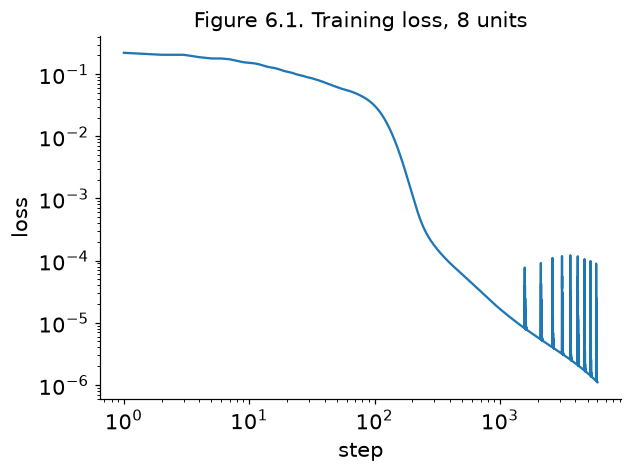

In [38]:
# c.6.4
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
ax.loglog(np.arange(1, len(lossHist) + 1), lossHist)
ax.set(xlabel="step", ylabel="loss", title="Figure 6.1. Training loss, 8 units")
plt.show()

*Figure 6.2. The network (solid) and f (dashed) at four moments of training.*

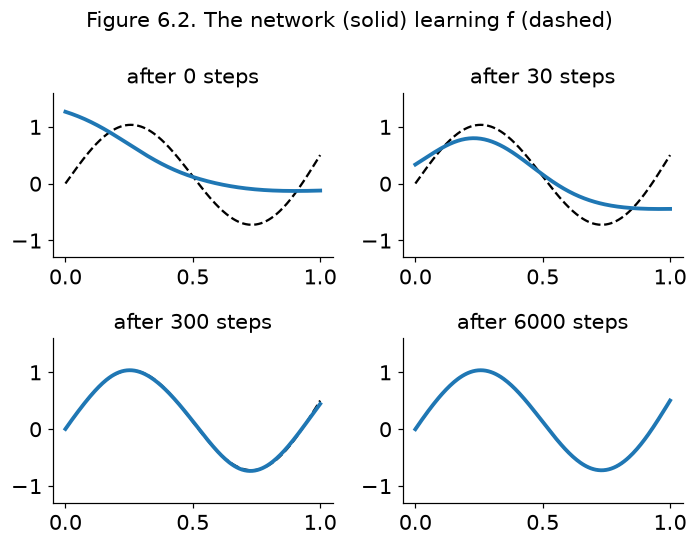

In [39]:
# c.6.5
fig, axs = panels(2, 2, "Figure 6.2. The network (solid) learning f (dashed)", h=0.8)
for ax, k in zip(axs.flat, (0, 30, 300, 6000)):
    ax.plot(xt, ft, "k--")
    ax.plot(xt, netOut(snaps[k], xt), lw=2.5)
    ax.set(ylim=(-1.3, 1.6), xticks=[0, 0.5, 1], title=f"after {k} steps")
fig.tight_layout()
plt.show()

*Figure 6.3. The trained network taken apart: the eight terms ${\alpha}_{j}$ σ(${y}_{j}$ x + ${\theta}_{j}$) (thin) and their sum plus c, which is the fit (thick). The units do not look like the steps of a staircase. Training finds large terms that cancel and leave a precise curve.*

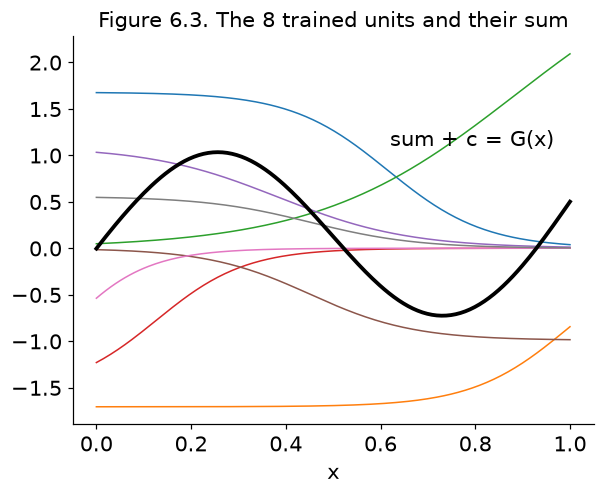

In [40]:
# c.6.6
# the trained network split into its 8 hidden units α_j σ(y_j x + θ_j);
# their sum plus the constant c is the fit
y_, t_, a_, c_ = unpack(pT)
units = a_ * logistic_sigmoid(np.outer(xt, y_) + t_)
fig, ax = plt.subplots(figsize=(wFull, 0.75 * wFull))
for j in range(nU):
    ax.plot(xt, units[:, j], color=C[j], lw=1)
ax.plot(xt, units.sum(axis=1) + c_, "k", lw=2.5)
ax.text(0.62, 1.1, "sum + c = G(x)", fontsize=figFont)
ax.set(xlabel="x", title="Figure 6.3. The 8 trained units and their sum")
plt.show()

*Table 6.3. The trained 8-unit network against staircases of Eq. (M7) with 8 and 80 units.*

In [41]:
# c.6.7
# trained weights against the staircase of Eq. (M7), on a fine grid
table([["construction", "units", "max error"],
       ["staircase, Eq. (M7)", 8, nf(supErrS(logistic_sigmoid, f, 8, 160), 3)],
       ["staircase, Eq. (M7)", 80, nf(supErrS(logistic_sigmoid, f, 80, 1600), 3)],
       ["trained with Eqs. (6.1)-(6.3)", 8, nf(np.max(np.abs(netOut(pT, xsFine) - f(xsFine))), 3)]], "Table 6.3")

construction,units,max error
"staircase, Eq. (M7)",8,0.276
"staircase, Eq. (M7)",80,0.0276
trained with Eqs. (6.1)-(6.3),8,0.00394


**Table 6.3**

| construction | units | max error |
|---|---|---|
| staircase, Eq. (M7) | 8 | 0.276 |
| staircase, Eq. (M7) | 80 | 0.0276 |
| trained with Eqs. (6.1)-(6.3) | 8 | 0.000809 |

The comparison makes the point of section 4 of the main notebook concrete. The staircase is a proof device: it shows that some weights exist. Trained weights are far better: 8 trained units reach an error of 4 × ${10}^{-3}$, while the staircase needs 80 units for 0.028 and would need several hundred to match.

### Answer

By the path rule of Eq. (M5): ∂G/∂${\alpha}_{j}$ = σ(${z}_{j}$), Eq. (6.1), and ∂G/∂${y}_{ji}$ = ${\alpha}_{j}$ σ′(${z}_{j}$) ${x}_{i}$, Eq. (6.3), with ${z}_{j}$ = ${y}_{j}$·x + ${\theta}_{j}$; also ∂G/∂${\theta}_{j}$ = ${\alpha}_{j}$ σ′(${z}_{j}$), Eq. (6.2). They agree with SymPy's exact derivatives to 3 × ${10}^{-17}$ (Table 6.1). Built into the loss gradient Eq. (6.4), they agree with finite differences to 3 × ${10}^{-11}$ and train an 8-unit network to a maximum error of 4 × ${10}^{-3}$.

## 7. Problem 7: rates from the modulus of continuity

**Problem 7.** Run the staircase of section 4 on x sin(1/x) (with value 0 at 0) and on the Cantor staircase of Figure M9. Predict the rate of convergence from the modulus of continuity, Eq. (M12), before you measure it.

*Figure 7.1. The two targets, with zooms. x sin(1/x) oscillates infinitely often near 0 with amplitude x; the Cantor staircase C repeats itself at every scale.*

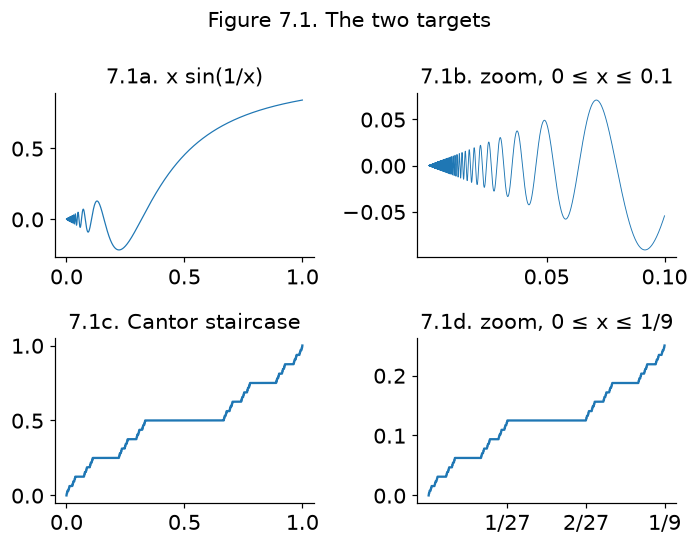

In [42]:
# c.7.1
# the two functions, safe on whole arrays (x sin(1/x) is 0 at 0)
def xsin(x):
    x = np.asarray(x, float)
    return x * np.sin(1 / (x + 1e-300))

def cantor(x, digits=40):
    """CantorStaircase from the ternary digits of x: a digit 1 ends the expansion."""
    x = np.clip(np.asarray(x, float), 0, 1)
    out, alive, r = np.zeros_like(x), np.ones_like(x, bool), x.copy()
    for k in range(1, digits + 1):
        r = 3 * r
        d = np.minimum(np.floor(r), 2)
        r -= d
        out += np.where(alive & (d >= 1), 0.5**k, 0.0)
        alive &= d != 1
    return np.where(x >= 1, 1.0, out)

targets = {"x sin(1/x)": xsin, "Cantor": cantor}
fig, axs = panels(2, 2, "Figure 7.1. The two targets", h=0.8)
x1 = np.linspace(0, 1, 40001); axs[0, 0].plot(x1, xsin(x1), lw=0.8); axs[0, 0].set_title("7.1a. x sin(1/x)")
x2 = np.linspace(0, 0.1, 40001); axs[0, 1].plot(x2, xsin(x2), lw=0.6)
axs[0, 1].set(xticks=[0.05, 0.1], title="7.1b. zoom, 0 ≤ x ≤ 0.1")
axs[1, 0].plot(x1, cantor(x1)); axs[1, 0].set_title("7.1c. Cantor staircase")
x3 = np.linspace(0, 1 / 9, 4001); axs[1, 1].plot(x3, cantor(x3))
axs[1, 1].set(xticks=[1 / 27, 2 / 27, 1 / 9], xticklabels=["1/27", "2/27", "1/9"], title="7.1d. zoom, 0 ≤ x ≤ 1/9")
fig.tight_layout()
plt.show()

### The prediction

The ideal staircase ${S}_{N}$ of Eq. (1.3) takes at x the value of f at the nearest node, which is at most 1/(2N) away. By the definition of the modulus of continuity, Eq. (M12),

$$
| {S}_{N} ( x ) - f ( x ) | \le {\omega}_{f} ( \frac{1}{2 N} ) , \text{error} \approx {\omega}_{f} ( \frac{1}{2 N} ) \quad  \tag{7.1}
$$

With λ = 20 N the logistic leakage is negligible (Problem 1), so the staircase error should be close to ${\omega}_{f}$(1/(2N)). Its rate is the rate of ${\omega}_{f}$. We work ${\omega}_{f}$ out for each target.

- x sin(1/x). Near a point a > 0 the function oscillates with amplitude about a, and one half-oscillation, a change of 1/x by π, takes a change of x by about π ${a}^{2}$. A window of width δ placed where π ${a}^{2}$ = δ therefore sees the full swing from +a to -a, and no better placement exists: to the left the amplitude is smaller, to the right the window covers less than a half-oscillation. So

$$
{\omega}_{f} ( \delta ) \approx 2 \sqrt{\frac{\delta}{\pi}} \quad  for \  f ( x ) = x \  \sin  ( \frac{1}{x} ) \quad  \tag{7.2}
$$

- Rate prediction: ${\omega}_{f}$(1/(2N)) ≈ 2√(1/(2πN)) = 0.80/√N, so the error should fall like ${N}^{-1/2}$, one factor √2 for each doubling of N.
- Cantor staircase. C satisfies the self-similarity C(x/3) = C(x)/2 and the symmetry C(1 - x) = 1 - C(x). An interval of length ${3}^{-k}$ rises by at most ${2}^{-k}$, and the first interval [0, ${3}^{-k}$] rises by exactly that:

$$
C ( \frac{x}{3} ) = \frac{C ( x )}{2} , C ( 1 - x ) = 1 - C ( x ) \quad  \implies \quad  {\omega}_{C} ( {3}^{- k} ) = {2}^{- k} \quad  \tag{7.3}
$$

- In between, ${\omega}_{C}$(δ) stays within a factor 2 of δ to the power ln 2/ln 3 = 0.631, so C is Hölder continuous with that exponent and no better. Rate prediction:

$$
{\omega}_{C} ( \delta ) \simeq {\delta}^{\ln  \  2 / \ln  \  3} , \text{error} \sim {N}^{- 1 / 2} and {N}^{- \ln  \  2 / \ln  \  3} \quad  \tag{7.4}
$$

The predictions are made. Now the measurements: first the moduli themselves, computed on a grid of 100001 points with a sliding maximum and minimum.

*Table 7.1. The modulus of continuity ${\omega}_{f}$(δ), measured and predicted by Eqs. (7.2) and (7.4).*

In [43]:
# c.7.2
# modulus of continuity, Eq. (M12), on a grid of step h: the largest
# range max - min of f over a window of width δ
h = 1e-5
grid = np.linspace(0., 1., 100001)
fGrid = {"x sin(1/x)": xsin(grid), "Cantor": cantor(grid)}
def omegaG(vals, d):
    r = round(d / (2 * h))
    return np.max(maximum_filter1d(vals, 2 * r + 1, mode="nearest") - minimum_filter1d(vals, 2 * r + 1, mode="nearest"))

# predictions, Eqs. (7.2) and (7.4)
omegaPred = {"x sin(1/x)": lambda d: 2 * np.sqrt(d / np.pi), "Cantor": lambda d: d**(np.log(2) / np.log(3))}
ds = 1. / np.array([5, 10, 20, 40, 80, 160, 320, 640])
rows = [["f", ""] + [f"δ = 1/{round(1 / d)}" for d in ds]]
for k in targets:
    rows.append([k, "measured"] + [nf(omegaG(fGrid[k], d), 3) for d in ds])
    rows.append(["", "predicted"] + [nf(omegaPred[k](d), 3) for d in ds])
table(rows, "Table 7.1")

f,,δ = 1/5,δ = 1/10,δ = 1/20,δ = 1/40,δ = 1/80,δ = 1/160,δ = 1/320,δ = 1/640
x sin(1/x),measured,0.548,0.346,0.268,0.191,0.133,0.0951,0.0672,0.0475
,predicted,0.505,0.357,0.252,0.178,0.126,0.0892,0.0631,0.0446
Cantor,measured,0.25,0.2,0.125,0.0667,0.0625,0.0312,0.0215,0.0156
,predicted,0.362,0.234,0.151,0.0975,0.063,0.0407,0.0263,0.017


**Table 7.1**

| f |  | δ = 1/5 | δ = 1/10 | δ = 1/20 | δ = 1/40 | δ = 1/80 | δ = 1/160 | δ = 1/320 | δ = 1/640 |
|---|---|---|---|---|---|---|---|---|---|
| x sin(1/x) | measured | 0.548 | 0.346 | 0.268 | 0.191 | 0.133 | 0.0951 | 0.0672 | 0.0475 |
|  | predicted | 0.505 | 0.357 | 0.252 | 0.178 | 0.126 | 0.0892 | 0.0631 | 0.0446 |
| Cantor | measured | 0.25 | 0.2 | 0.125 | 0.0667 | 0.0625 | 0.0313 | 0.0215 | 0.0156 |
|  | predicted | 0.362 | 0.234 | 0.151 | 0.0975 | 0.063 | 0.0407 | 0.0263 | 0.017 |

*Figure 7.2. The moduli on log-log axes, with lines of slope 1/2 and ln 2/ln 3 (dashed).*

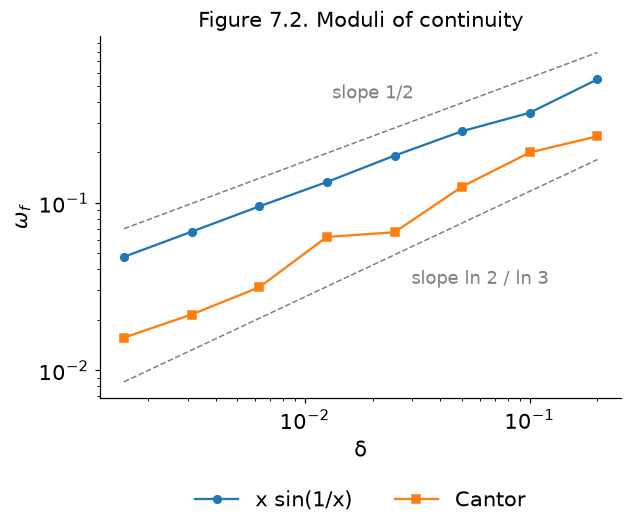

In [44]:
# c.7.3
fig, ax = plt.subplots(figsize=(wFull, 0.7 * wFull))
for i, k in enumerate(targets):
    ax.loglog(ds, [omegaG(fGrid[k], d) for d in ds], marker=mk[i], ms=5, label=k)
logLine(ax, [[1 / 640, 0.07], [1 / 5, 0.07 * np.sqrt(128)]])
logLine(ax, [[1 / 640, 0.0085], [1 / 5, 0.0085 * 128**(np.log(2) / np.log(3))]])
logText(ax, "slope 1/2", (0.02, 0.45))
logText(ax, "slope ln 2 / ln 3", (0.06, 0.035))
ax.set(xlabel="δ", ylabel="$\\omega_f$", title="Figure 7.2. Moduli of continuity")
legend_below(ax, ncol=2)
plt.show()

### The measurement

The staircase of Eq. (M7) with λ = 20 N, measured on a grid that has a spacing of 2 × ${10}^{-5}$ on [0, 0.3], where x sin(1/x) oscillates fastest. For the Cantor staircase we use both N = ${3}^{k}$, which fits its self-similarity, and the values of N used for x sin(1/x).

*Table 7.2. The prediction ${\omega}_{f}$(1/(2N)) of Eq. (7.1) against the measured error. The ratio is never above 1: Eq. (7.1) is an upper bound that is nearly attained.*

In [45]:
# c.7.4
# the prediction, made before measuring:
# error ≈ ω_f(1/(2N)), Eq. (7.1)
nsP = [5, 10, 20, 40, 80, 160, 320, 640]
nsC = [3**k for k in range(1, 7)]
def predErr(k, n):
    return omegaG(fGrid[k], 1. / (2 * n))

# the measurement: sup error of the staircase of Eq. (M7), λ = 20 N,
# on a grid that is dense where x sin(1/x) oscillates
xsM = np.union1d(np.linspace(0., 0.3, 15001), np.linspace(0.3, 1., 3501))
fM = {k: fn(xsM) for k, fn in targets.items()}   # f on that grid, computed once
def measErr(k, n):
    vals = targets[k](nodes(n))
    # in blocks of points, to keep the len(xsM) x N matrix small
    return max(np.max(np.abs(fM[k][i:i + 2000] - stairOn(logistic_sigmoid, vals, 20 * n, xsM[i:i + 2000])))
               for i in range(0, len(xsM), 2000))

errTab = {"x sin(1/x)": np.array([[n, predErr("x sin(1/x)", n), measErr("x sin(1/x)", n)] for n in nsP]),
          "Cantor": np.array([[n, predErr("Cantor", n), measErr("Cantor", n)] for n in nsC + nsP])}
rows = [["f", "N", "predicted ω(1/(2N))", "measured error", "ratio"]]
for k, tab in errTab.items():
    for i, (n, pe, me) in enumerate(tab):
        rows.append([k if i == 0 else "", int(n), nf(pe, 3), nf(me, 3), nf(me / pe, 3)])
table(rows, "Table 7.2")

f,N,predicted ω(1/(2N)),measured error,ratio
x sin(1/x),5,0.346,0.311,0.901
,10,0.268,0.185,0.691
,20,0.191,0.148,0.772
,40,0.133,0.104,0.78
,80,0.0951,0.081,0.852
,160,0.0672,0.0528,0.786
,320,0.0475,0.0431,0.908
,640,0.0336,0.0316,0.94
Cantor,3,0.25,0.233,0.931
,9,0.125,0.116,0.931


**Table 7.2**

| f | N | predicted ω(1/(2N)) | measured error | ratio |
|---|---|---|---|---|
| x sin(1/x) | 5 | 0.346 | 0.311 | 0.901 |
|  | 10 | 0.268 | 0.185 | 0.691 |
|  | 20 | 0.191 | 0.148 | 0.772 |
|  | 40 | 0.133 | 0.104 | 0.78 |
|  | 80 | 0.0951 | 0.081 | 0.852 |
|  | 160 | 0.0672 | 0.0528 | 0.786 |
|  | 320 | 0.0475 | 0.0431 | 0.908 |
|  | 640 | 0.0336 | 0.0316 | 0.94 |
| Cantor | 3 | 0.25 | 0.233 | 0.931 |
|  | 9 | 0.125 | 0.116 | 0.931 |
|  | 27 | 0.0625 | 0.0582 | 0.931 |
|  | 81 | 0.0313 | 0.0291 | 0.931 |
|  | 243 | 0.0156 | 0.0145 | 0.93 |
|  | 729 | 0.00781 | 0.00727 | 0.931 |
|  | 5 | 0.2 | 0.136 | 0.682 |
|  | 10 | 0.125 | 0.111 | 0.889 |
|  | 20 | 0.0667 | 0.0617 | 0.926 |
|  | 40 | 0.0625 | 0.0408 | 0.653 |
|  | 80 | 0.0313 | 0.0292 | 0.936 |
|  | 160 | 0.0215 | 0.0155 | 0.722 |
|  | 320 | 0.0156 | 0.0118 | 0.752 |
|  | 640 | 0.00781 | 0.00765 | 0.979 |

*Table 7.3. Rates: the exponent predicted from ω, the slope of the predicted errors, and the slope of the measured errors, by least squares in log-log coordinates.*

In [46]:
# c.7.5
# rates: least-squares slopes of log(error) against log N
def slope(pts):
    return np.polyfit(np.log(pts[:, 0]), np.log(pts[:, 1]), 1)[0]

xs_, cs = errTab["x sin(1/x)"], errTab["Cantor"]
r = np.log(2) / np.log(3)
table([["f", "range", "rate from ω", "slope of ω(1/(2N))", "slope of measured error"],
       ["x sin(1/x)", "N = 5 ... 640", "-1/2 = -0.5", nf(slope(xs_[:, [0, 1]]), 3), nf(slope(xs_[:, [0, 2]]), 3)],
       ["Cantor", "N = 3 ... 729", f"-ln 2/ln 3 = {nf(-r, 3)}", nf(slope(cs[:6, [0, 1]]), 3), nf(slope(cs[:6, [0, 2]]), 3)],
       ["Cantor", "N = 5 ... 640", f"-ln 2/ln 3 = {nf(-r, 3)}", nf(slope(cs[6:, [0, 1]]), 3), nf(slope(cs[6:, [0, 2]]), 3)]],
      "Table 7.3")

f,range,rate from ω,slope of ω(1/(2N)),slope of measured error
x sin(1/x),N = 5 ... 640,-1/2 = -0.5,-0.489,-0.458
Cantor,N = 3 ... 729,-ln 2/ln 3 = -0.631,-0.631,-0.631
Cantor,N = 5 ... 640,-ln 2/ln 3 = -0.631,-0.639,-0.616


**Table 7.3**

| f | range | rate from ω | slope of ω(1/(2N)) | slope of measured error |
|---|---|---|---|---|
| x sin(1/x) | N = 5 ... 640 | -1/2 = -0.5 | -0.489 | -0.458 |
| Cantor | N = 3 ... 729 | -ln 2/ln 3 = -0.631 | -0.631 | -0.631 |
| Cantor | N = 5 ... 640 | -ln 2/ln 3 = -0.631 | -0.639 | -0.616 |

*Figure 7.3. Measured errors (marks) and the predictions ${\omega}_{f}$(1/(2N)) (dashed).*

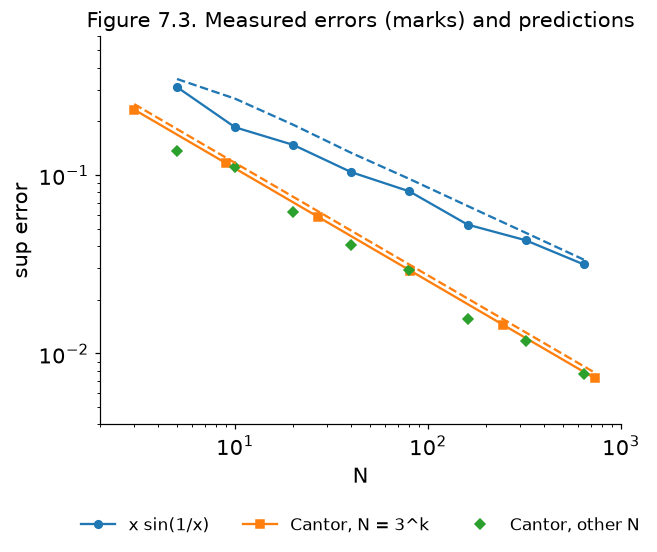

In [47]:
# c.7.6
fig, ax = plt.subplots(figsize=(wFull, 0.75 * wFull))
ax.loglog(xs_[:, 0], xs_[:, 2], marker="o", ms=5, color=C[0], label="x sin(1/x)")
ax.loglog(cs[:6, 0], cs[:6, 2], marker="s", ms=5, color=C[1], label="Cantor, N = 3^k")
ax.loglog(cs[6:, 0], cs[6:, 2], "D", ms=5, color=C[2], label="Cantor, other N")
ax.loglog(xs_[:, 0], xs_[:, 1], "--", color=C[0])
ax.loglog(cs[:6, 0], cs[:6, 1], "--", color=C[1])
ax.set(xlim=(2, 1000), ylim=(0.004, 0.6), xlabel="N", ylabel="sup error",
       title="Figure 7.3. Measured errors (marks) and predictions")
legend_below(ax, ncol=3, fontsize=figFont - 3)
plt.show()

*Figure 7.4. Where the error lives. For x sin(1/x) it is largest around x ≈ 0.1, where the oscillations are as wide as the steps; for the Cantor staircase it sits on the rising parts, the Cantor set, and is zero on the flat parts.*

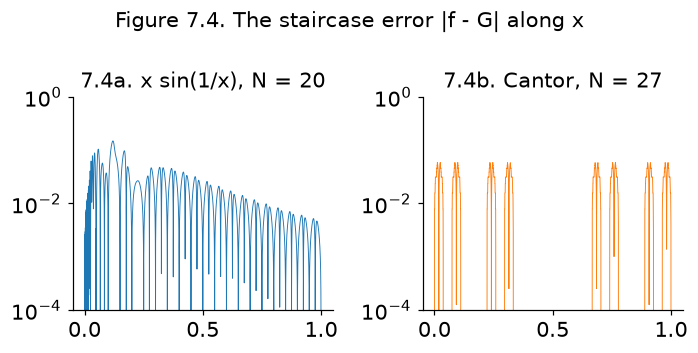

In [48]:
# c.7.7
# where the error lives: |f - G_N| along x, N = 20 and N = 27
fig, axs = panels(1, 2, "Figure 7.4. The staircase error |f - G| along x", h=1.0)
e1 = np.abs(fM["x sin(1/x)"] - stairOn(logistic_sigmoid, xsin(nodes(20)), 400, xsM)) + 1e-12
e2 = np.abs(fM["Cantor"] - stairOn(logistic_sigmoid, cantor(nodes(27)), 540, xsM)) + 1e-12
axs[0, 0].semilogy(xsM, e1, lw=0.6, color=C[0]); axs[0, 0].set_title("7.4a. x sin(1/x), N = 20")
axs[0, 1].semilogy(xsM, e2, lw=0.6, color=C[1]); axs[0, 1].set_title("7.4b. Cantor, N = 27")
for ax in axs[0]:
    ax.set(ylim=(1e-4, 1), xticks=[0, 0.5, 1])
fig.tight_layout()
plt.show()

### Answer

- x sin(1/x): predicted ω(δ) ≈ 2√(δ/π), so the error should behave like ${N}^{-1/2}$. Measured slope -0.46 over N = 5 ... 640, a little flatter than -1/2 because the error approaches the bound ${\omega}_{f}$(1/(2N)) from below: their ratio drifts upward, from 0.69–0.78 at N = 10–40 to 0.94 at N = 640.
- Cantor staircase: predicted ω(${3}^{-k}$) = ${2}^{-k}$, so the error should behave like N to the power -ln 2/ln 3 = -0.631. Measured slope -0.631 for N = ${3}^{k}$, where the error is exactly 0.931 ${\omega}_{C}$(1/(2N)) at every k, and -0.62 for the other N.
- Both functions are continuous on [0, 1], so by Theorem M9 they are uniformly continuous, ${\omega}_{f}$(1/N) → 0, and the staircase converges, as Cybenko's theorem requires. The modulus of continuity predicts the rate: neither function is Lipschitz, and both converge more slowly than the O(1/N) of the smooth example A.

## References

- S Shape Functions Theory, the main notebook: D. O Shayda, N. Hoshino, Computational Classnotes (2026).
- G. Cybenko, Approximation by superpositions of a sigmoidal function, Math. Control Signals Systems 2 (1989) 303–314. doi:10.1007/BF02551274
- K. Hornik, M. Stinchcombe, H. White, Multilayer feedforward networks are universal approximators, Neural Networks 2 (1989) 359–366. doi:10.1016/0893-6080(89)90020-8
- K. Hornik, Approximation capabilities of multilayer feedforward networks, Neural Networks 4 (1991) 251–257.
- M. Leshno, V. Ya. Lin, A. Pinkus, S. Schocken, Multilayer feedforward networks with a nonpolynomial activation function can approximate any function, Neural Networks 6 (1993) 861–867. doi:10.1016/S0893-6080(05)80131-5
- A. N. Kolmogorov, On the representation of continuous functions of many variables by superposition of continuous functions of one variable and addition, Dokl. Akad. Nauk SSSR 114 (1957) 953–956.
- D. E. Rumelhart, G. E. Hinton, R. J. Williams, Learning representations by back-propagating errors, Nature 323 (1986) 533–536. doi:10.1038/323533a0
- D. P. Kingma, J. Ba, Adam: A method for stochastic optimization, ICLR 2015, arXiv:1412.6980.
- P. J. Werbos, Backpropagation through time: what it does and how to do it, Proc. IEEE 78 (1990) 1550–1560. doi:10.1109/5.58337
- Wolfram Research, BasicRecurrentLayer, Wolfram Language documentation, reference.wolfram.com/language/ref/BasicRecurrentLayer.html

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>